In [2]:
import json, re, subprocess, tempfile, shutil, hashlib
from pathlib import Path

import pandas as pd
import numpy as np
import plotly.graph_objects as go
import plotly.express as px
from plotly.subplots import make_subplots

import plotly.io as pio
pio.renderers.default = 'png'
pio.renderers['png'].width = 1100
pio.renderers['png'].scale = 2
import requests
from tqdm.auto import tqdm

OUTPUT_DIR = Path('output/dpiac_security_audit')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

BENCHMARK_CSV  = Path('Data/iac_basic.csv')
TEMPLATE_ROOT  = Path('Data/groud_truth/template')

SEV_COLORS = {
    'CRITICAL': '#B22222', 'HIGH': '#EF553B',
    'MEDIUM':   '#FFA15A', 'LOW':  '#636EFA', 'UNKNOWN': '#AAAAAA',
}

SAVE_EVERY = 5
CFNLINT_CACHE_PATH = OUTPUT_DIR / 'dpiac_gt_cfnlint_cache.csv'
TRIVY_CACHE_PATH   = OUTPUT_DIR / 'dpiac_gt_trivy_cache.csv'
CHECKOV_CACHE_PATH = OUTPUT_DIR / 'dpiac_gt_checkov_cache.csv'

In [3]:
_LIST_COLS = {'violation_ids', 'violation_titles', 'violations'}

def _encode_cache_row(row: dict) -> dict:
    out = dict(row)
    for k in _LIST_COLS:
        if k in out and not isinstance(out[k], str):
            out[k] = json.dumps(out[k])
    return out

def _flush_cache(path: Path, batch: list) -> None:
    if not batch:
        return
    df_batch = pd.DataFrame([_encode_cache_row(r) for r in batch])
    has_header = path.exists() and path.stat().st_size > 0
    if has_header:
        existing_cols = pd.read_csv(path, nrows=0).columns
        df_batch = df_batch.reindex(columns=existing_cols)
    df_batch.to_csv(path, mode='a', header=not has_header, index=False)

def resumable_scan(df_src: pd.DataFrame, key_col: str, scan_fn, cache_path: Path, desc: str) -> pd.DataFrame:
    done_ids = set()
    if cache_path.exists():
        done_ids = set(pd.read_csv(cache_path, usecols=[key_col])[key_col])
    todo = df_src[~df_src[key_col].isin(done_ids)].drop_duplicates(subset=key_col)
    print(f"📂 {desc}: {len(done_ids)} cached, {len(todo)} to scan")

    batch = []
    for _, row in tqdm(todo.iterrows(), total=len(todo), desc=desc, unit='template'):
        rec = scan_fn(row)
        rec[key_col] = row[key_col]
        batch.append(rec)
        if len(batch) >= SAVE_EVERY:
            _flush_cache(cache_path, batch)
            batch = []
    _flush_cache(cache_path, batch)

    out = pd.read_csv(cache_path)
    for k in _LIST_COLS:
        if k in out.columns:
            out[k] = out[k].apply(lambda v: json.loads(v) if isinstance(v, str) else [])
    return out

In [4]:
_TRIVY_TREE_API = (
    "https://api.github.com/repos/aquasecurity/trivy-checks/"
    "git/trees/HEAD?recursive=1"
)

def build_avd_title_map() -> dict[str, str]:
    title_map: dict[str, str] = {}
    resp = requests.get(_TRIVY_TREE_API, timeout=30)
    resp.raise_for_status()
    tree = resp.json().get('tree', [])

    rego_paths = [
        item['path'] for item in tree
        if item['path'].startswith('checks/cloud/aws/')
        and item['path'].endswith('.rego')
        and not item['path'].endswith('_test.rego')
        and 'lib/' not in item['path']
    ]
    print(f"  Found {len(rego_paths)} AWS .rego files — downloading...")
    raw_base = "https://raw.githubusercontent.com/aquasecurity/trivy-checks/HEAD/"

    for path in rego_paths:
        try:
            r = requests.get(raw_base + path, timeout=15)
            r.raise_for_status()
            content = r.text
        except Exception:
            continue
        title_match = re.search(r'^# title:\s*(.+)$',         content, re.MULTILINE)
        id_match    = re.search(r'^#\s+id:\s*(AWS-\d+)\s*$',  content, re.MULTILINE)
        if not title_match or not id_match:
            continue
        title    = title_match.group(1).strip()
        short_id = id_match.group(1).strip()
        title_map[short_id]          = title
        title_map[f"AVD-{short_id}"] = title

    print(f"  Registry built: {len(title_map)} entries")
    return title_map

AVD_TITLE_MAP = build_avd_title_map()

  Found 175 AWS .rego files — downloading...


  Registry built: 350 entries


In [5]:
_SEV_MAP = {
    'CRITICAL': 'severity_critical', 'HIGH': 'severity_high',
    'MEDIUM':   'severity_medium',   'LOW':  'severity_low',
    'UNKNOWN':  'severity_unknown',
}
_AWS_PREFIXES = ('AVD-AWS-', 'AWS-')

EXCLUDE_IDS = {
}

def run_trivy_cfn(template_path: Path, timeout: int = 90) -> dict:
    result = dict(
        trivy_passed=False, trivy_error=None,
        total_checks=0, passed_checks=0, failed_checks=0,
        policy_pass_rate=None, fully_compliant=False,
        severity_critical=0, severity_high=0, severity_medium=0,
        severity_low=0, severity_unknown=0,
        violations=[], violation_ids=[], violation_titles=[],
    )

    if not template_path.exists():
        result['trivy_error'] = f'file_not_found: {template_path}'
        return result

    cmd = [
        'trivy', 'config',
        '--format', 'json',
        '--quiet',
        '--include-non-failures',
        str(template_path),
    ]
    try:
        proc = subprocess.run(cmd, capture_output=True, text=True, timeout=timeout)
    except subprocess.TimeoutExpired:
        result['trivy_error'] = 'TimeoutExpired'; return result
    except FileNotFoundError:
        result['trivy_error'] = 'trivy_not_found'; return result
    except Exception as e:
        result['trivy_error'] = str(e); return result

    try:
        raw = json.loads(proc.stdout)
    except json.JSONDecodeError:
        result['trivy_error'] = 'json_parse_failed'; return result

    results_list = raw.get('Results', [])

    if not any(r.get('Type') == 'cloudformation' for r in results_list):
        result['trivy_error'] = 'not_scanned_by_trivy'
        return result

    use_results  = [r for r in results_list if r.get('Target', '') != '.'] or results_list

    total_passed = total_failed = 0

    for res in use_results:
        summary     = res.get('MisconfSummary', {})
        all_misconfs = res.get('Misconfigurations', [])

        valid = [
            m for m in all_misconfs
            if any(m.get('ID', '').startswith(p) for p in _AWS_PREFIXES)
            and m.get('ID', '') not in EXCLUDE_IDS
            and (m.get('Status') or 'FAIL').upper() == 'FAIL'
        ]

        total_failed  += len(valid)
        total_passed  += int(summary.get('Successes', 0))

        for m in valid:
            check_id    = m.get('ID', '')
            check_title = AVD_TITLE_MAP.get(check_id, m.get('Title', check_id))
            sev         = (m.get('Severity') or 'UNKNOWN').upper()
            cause       = m.get('CauseMetadata', {})
            resource    = cause.get('Resource', res.get('Target', ''))
            resource_type = resource.split('.')[0] if '.' in resource else resource

            result['violations'].append({
                'check_id':     check_id,
                'check_title':  check_title,
                'resource':     resource,
                'resource_type': resource_type,
                'severity':     sev,
                'status':       m.get('Status', ''),
                'description':  m.get('Description', ''),
                'resolution':   m.get('Resolution', ''),
            })
            result['violation_ids'].append(check_id)
            result['violation_titles'].append(check_title)
            result[_SEV_MAP.get(sev, 'severity_unknown')] += 1

    result['passed_checks']  = total_passed
    result['failed_checks']  = total_failed
    result['total_checks']   = total_passed + total_failed
    if result['total_checks'] > 0:
        result['policy_pass_rate'] = round(total_passed / result['total_checks'], 4)
    result['fully_compliant'] = result['total_checks'] > 0 and total_failed == 0
    result['trivy_passed']    = result['fully_compliant']
    return result

In [6]:
from pathlib import PureWindowsPath

df = pd.read_csv(BENCHMARK_CSV)
print(f"Loaded {len(df)} scenarios")

df['template_path'] = df['ground_truth_path'].apply(
    lambda p: TEMPLATE_ROOT / PureWindowsPath(p).name
)

print(df.head(3)[['row_number','template_path','prompt']].to_string())

missing = df[~df['template_path'].apply(lambda p: p.exists())]
if len(missing):
    print(f"⚠️  {len(missing)} templates not found locally:")
    print(missing[['row_number','ground_truth_path']].to_string())
else:
    print("✅  All templates found locally")

Loaded 153 scenarios
   row_number                            template_path                                                                                                         prompt
0           0  Data/groud_truth/template/sqs_easy.yaml                      We need a CloudFormation template that creates an AWS SQS queue with basic configuration.
1           1  Data/groud_truth/template/sns_easy.yaml  We need a CloudFormation template that creates an AWS SNS with notification sending to email "test@test.com".
2           2   Data/groud_truth/template/s3_easy.yaml                               We need a CloudFormation template that creates an Amazon S3 bucket with defaults
✅  All templates found locally


In [7]:
df_scan = resumable_scan(
    df, 'row_number',
    lambda row: run_trivy_cfn(row['template_path']),
    TRIVY_CACHE_PATH, 'Trivy CFn scan',
)
df_scan = df[['row_number']].merge(df_scan, on='row_number', how='left')

SCALAR_COLS = [
    'trivy_passed','trivy_error','total_checks','passed_checks','failed_checks',
    'policy_pass_rate','fully_compliant',
    'severity_critical','severity_high','severity_medium','severity_low','severity_unknown',
]
df_result = df[['row_number','prompt']].copy()
df_result['template'] = df['ground_truth_path'].apply(lambda p: Path(p).name)
for c in SCALAR_COLS:
    df_result[c] = df_scan[c]
df_result['violation_ids']    = df_scan['violation_ids']
df_result['violation_titles'] = df_scan['violation_titles']
df_result['violations_json']  = df_scan['violations'].apply(json.dumps)

df_result['swvs'] = (
    df_result['severity_critical'] * 4 + df_result['severity_high']     * 3 +
    df_result['severity_medium']   * 2 + df_result['severity_low']      * 1 +
    df_result['severity_unknown']  * 0.5
)

n_unscanned = (df_result['trivy_error'] == 'not_scanned_by_trivy').sum()
print(f"\nScan complete")
print(f"  Scenarios scanned     : {len(df_result):,}")
print(f"  Not scanned by Trivy  : {n_unscanned:,}  (excluded from FCR/PPR by construction — flagged for audit)")
print(f"  Fully compliant (FCR) : {df_result['fully_compliant'].sum():,}  ({df_result['fully_compliant'].mean()*100:.1f}%)")
print(f"  Mean PPR              : {df_result['policy_pass_rate'].mean()*100:.1f}%")
print(f"  Total violations      : {df_result['failed_checks'].sum():,}")
df_result.head()

📂 Trivy CFn scan: 0 cached, 153 to scan


Trivy CFn scan:   0%|          | 0/153 [00:00<?, ?template/s]


Scan complete
  Scenarios scanned     : 153
  Not scanned by Trivy  : 7  (excluded from FCR/PPR by construction — flagged for audit)
  Fully compliant (FCR) : 28  (18.3%)
  Mean PPR              : 90.2%
  Total violations      : 584


,row_number,prompt,template,trivy_passed,trivy_error,total_checks,passed_checks,failed_checks,policy_pass_rate,fully_compliant,severity_critical,severity_high,severity_medium,severity_low,severity_unknown,violation_ids,violation_titles,violations_json,swvs
0,0,We need a CloudFormation template that creates...,Data\groud_truth\template\sqs_easy.yaml,False,NaN,27,26,1,0.9630,False,0,1,0,0,0,[AWS-0096],[Unencrypted SQS queue.],"[{""check_id"": ""AWS-0096"", ""check_title"": ""Unen...",3.0
1,1,We need a CloudFormation template that creates...,Data\groud_truth\template\sns_easy.yaml,False,NaN,26,25,1,0.9615,False,0,1,0,0,0,[AWS-0095],[Unencrypted SNS topic.],"[{""check_id"": ""AWS-0095"", ""check_title"": ""Unen...",3.0
2,2,We need a CloudFormation template that creates...,Data\groud_truth\template\s3_easy.yaml,False,NaN,34,26,8,0.7647,False,0,5,1,2,0,"[AWS-0086, AWS-0087, AWS-0089, AWS-0090, AWS-0...","[S3 Access block should block public ACL, S3 A...","[{""check_id"": ""AWS-0086"", ""check_title"": ""S3 A...",19.0
3,3,We need a CloudFormation template that creates...,Data\groud_truth\template\s3_webhost_and_delet...,False,NaN,34,27,7,0.7941,False,0,5,1,1,0,"[AWS-0086, AWS-0087, AWS-0089, AWS-0090, AWS-0...","[S3 Access block should block public ACL, S3 A...","[{""check_id"": ""AWS-0086"", ""check_title"": ""S3 A...",18.0
4,4,We need a CloudFormation template that creates...,Data\groud_truth\template\ec2_easy.yaml,False,NaN,44,42,2,0.9545,False,0,2,0,0,0,"[AWS-0028, AWS-0131]",[aws_instance should activate session tokens f...,"[{""check_id"": ""AWS-0028"", ""check_title"": ""aws_...",6.0


In [8]:
df_annotated = df_result[[
    'row_number','template','prompt',
    'failed_checks','policy_pass_rate','swvs',
    'severity_critical','severity_high','severity_medium','severity_low',
    'fully_compliant','violation_ids',
]].copy()

df_annotated['violation_ids_str'] = df_annotated['violation_ids'].apply(
    lambda ids: ' | '.join(sorted(set(ids))) if ids else '✅ NONE'
)
df_annotated['policy_pass_rate_pct'] = (df_annotated['policy_pass_rate'] * 100).round(1)

df_annotated.drop(columns=['violation_ids']).to_csv(
    OUTPUT_DIR / 'dpiac_gt_security_annotations.csv', index=False
)
print("Saved → dpiac_gt_security_annotations.csv")
df_annotated[['row_number','template','failed_checks','violation_ids_str']].head(20)

Saved → dpiac_gt_security_annotations.csv


,row_number,template,failed_checks,violation_ids_str
0,0,Data\groud_truth\template\sqs_easy.yaml,1,AWS-0096
1,1,Data\groud_truth\template\sns_easy.yaml,1,AWS-0095
2,2,Data\groud_truth\template\s3_easy.yaml,8,AWS-0086 | AWS-0087 | AWS-0089 | AWS-0090 | AW...
3,3,Data\groud_truth\template\s3_webhost_and_delet...,7,AWS-0086 | AWS-0087 | AWS-0089 | AWS-0090 | AW...
4,4,Data\groud_truth\template\ec2_easy.yaml,2,AWS-0028 | AWS-0131
5,5,Data\groud_truth\template\DynamoDB_easy.yaml,2,AWS-0024 | AWS-0025
6,6,Data\groud_truth\template\EC2InstanceWithSecur...,3,AWS-0028 | AWS-0124 | AWS-0131
7,7,Data\groud_truth\template\virtualmachine.yaml,3,AWS-0028 | AWS-0131 | AWS-0178
8,8,Data\groud_truth\template\CloudWatch_Dashboard...,0,✅ NONE
9,9,Data\groud_truth\template\EFS_encrypted_one_zo...,1,AWS-0178


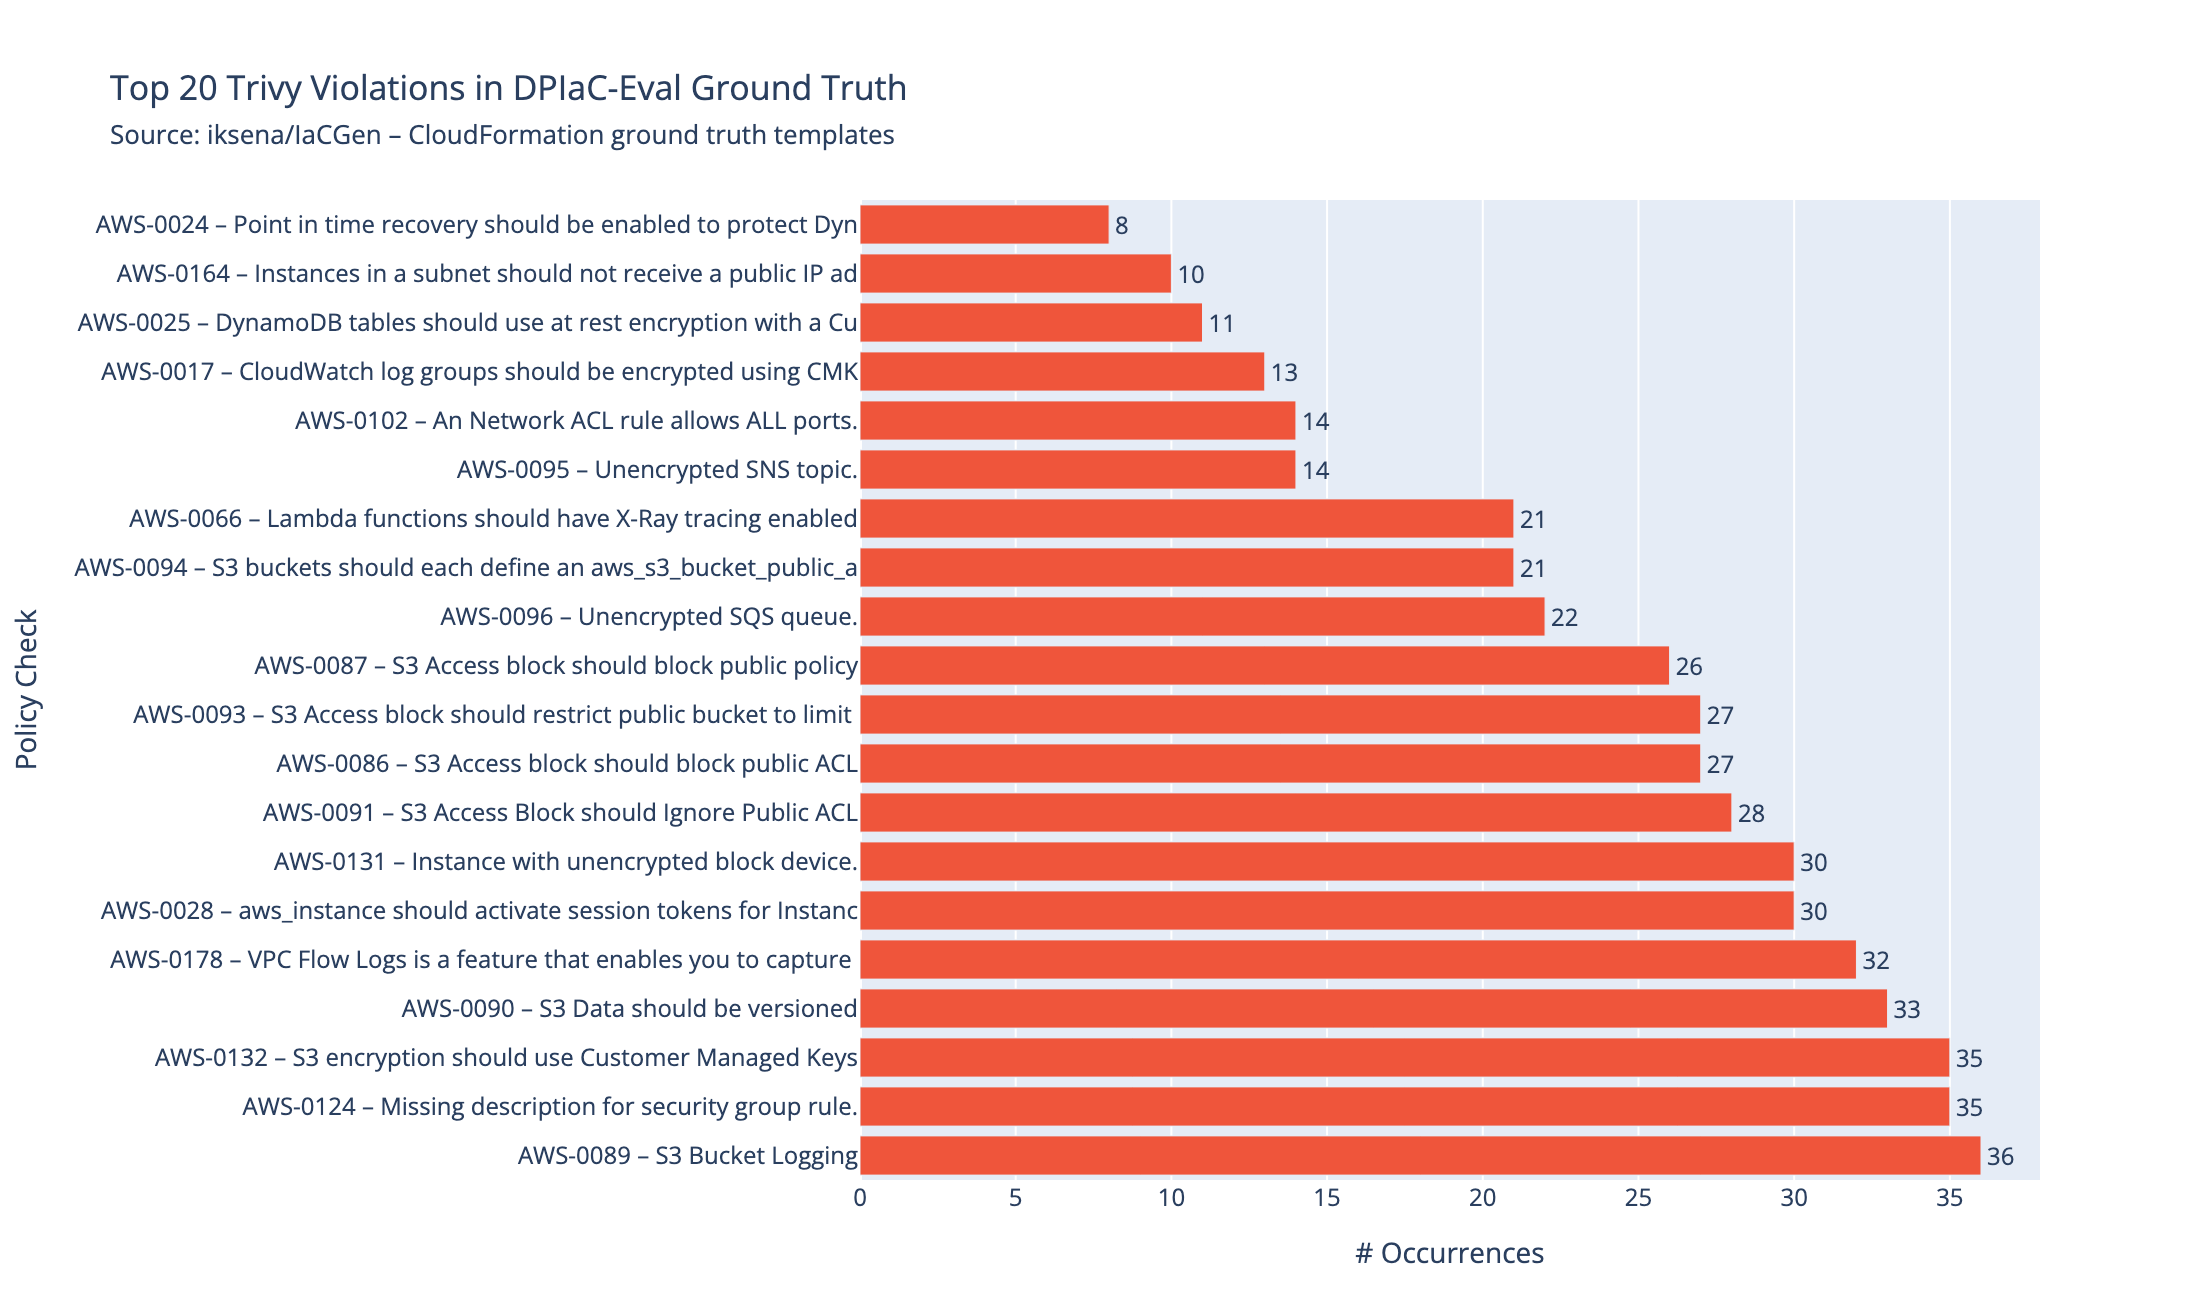

In [9]:
all_violations = []
for vj in df_result['violations_json']:
    try: all_violations.extend(json.loads(vj))
    except: pass

df_viol = pd.DataFrame(all_violations)
if not df_viol.empty:
    df_viol['check_title'] = df_viol['check_id'].map(AVD_TITLE_MAP).fillna(df_viol['check_title'])

top_checks = (
    df_viol.groupby(['check_id','check_title'])
    .size().reset_index(name='count')
    .sort_values('count', ascending=False)
).head(20)

top_checks['label'] = top_checks.apply(
    lambda r: f"{r['check_id']} – {r['check_title'][:55]}", axis=1
)

fig1 = go.Figure(go.Bar(
    x=top_checks['count'], y=top_checks['label'],
    orientation='h', text=top_checks['count'],
    textposition='outside', cliponaxis=False,
    marker_color='#EF553B',
))
fig1.update_layout(
    title="Top 20 Trivy Violations in DPIaC-Eval Ground Truth<br>"
          "<span style='font-size:13px;font-weight:normal;'>"
          "Source: iksena/IaCGen – CloudFormation ground truth templates</span>",
    xaxis_title='# Occurrences', yaxis_title='Policy Check',
    margin=dict(l=420, r=80, t=100, b=60), height=650,
)
top_checks.to_csv(OUTPUT_DIR / 'top20_violations.csv', index=False)
fig1.show()

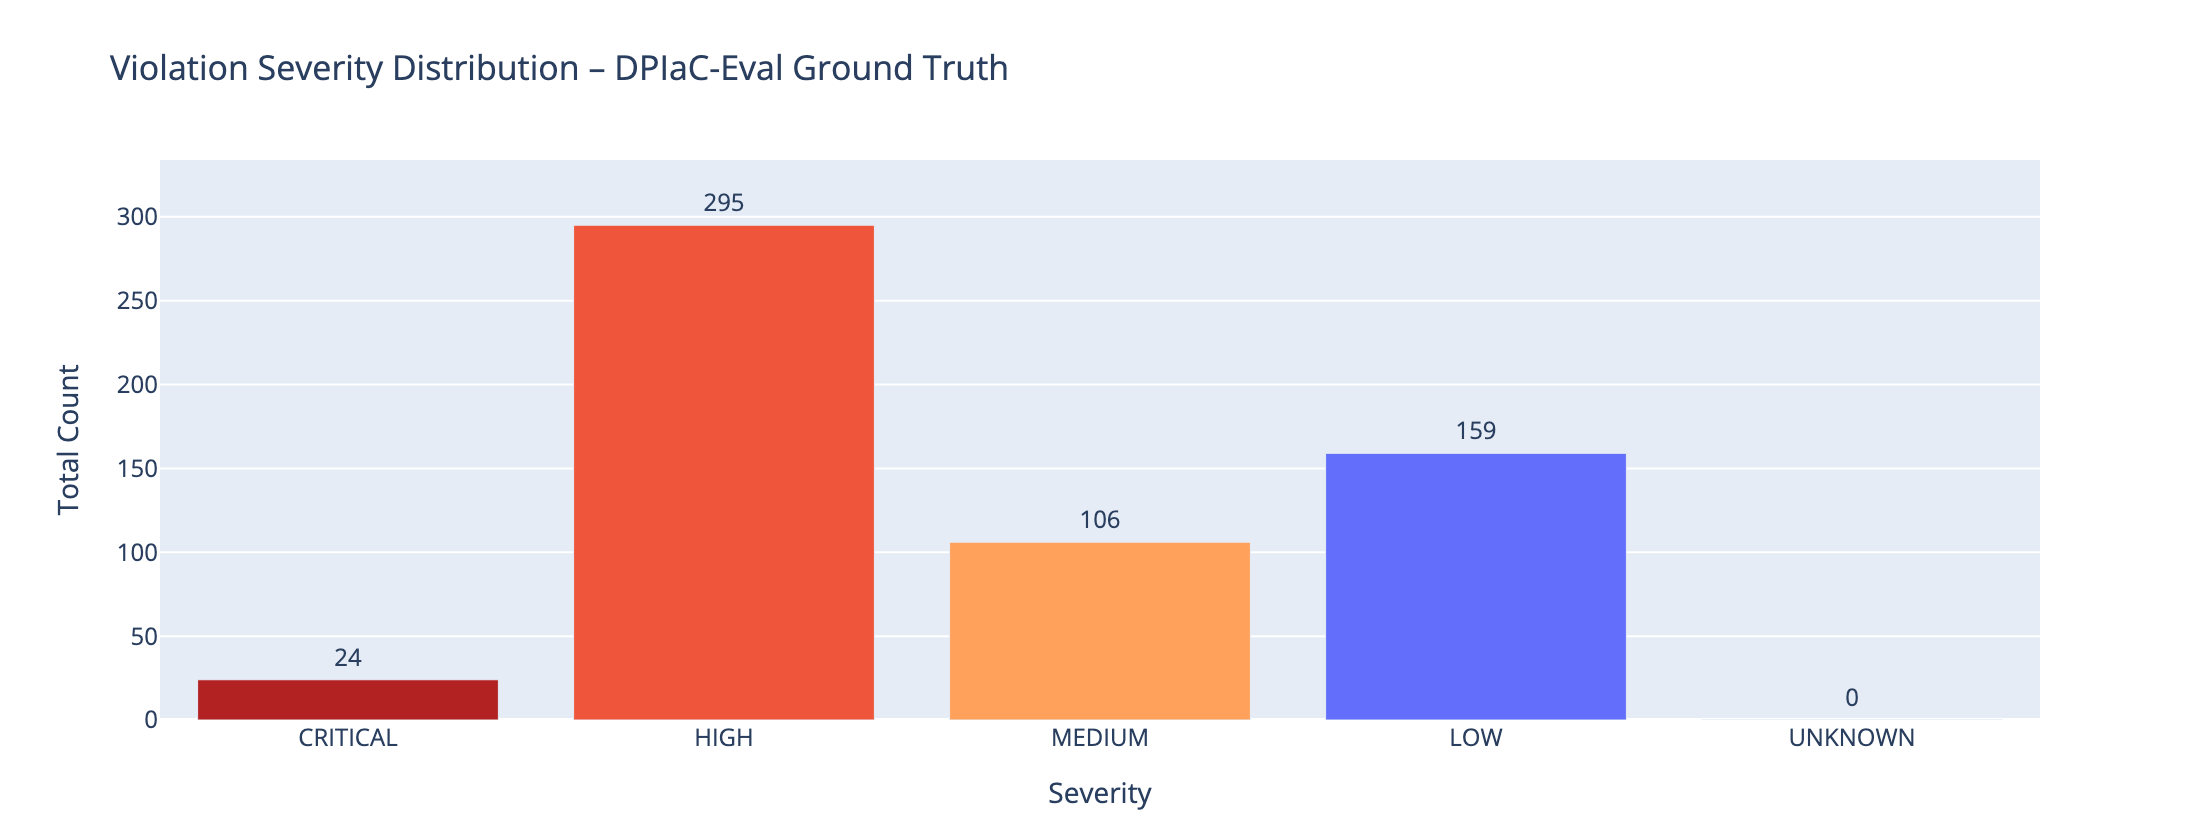

In [10]:
sev_totals = {
    s: int(df_result[c].sum())
    for s, c in [('CRITICAL','severity_critical'),('HIGH','severity_high'),
                 ('MEDIUM','severity_medium'),('LOW','severity_low'),('UNKNOWN','severity_unknown')]
}
fig2 = go.Figure(go.Bar(
    x=list(sev_totals.keys()), y=list(sev_totals.values()),
    marker_color=[SEV_COLORS[s] for s in sev_totals],
    text=list(sev_totals.values()), textposition='outside',
))
fig2.update_layout(
    title='Violation Severity Distribution – DPIaC-Eval Ground Truth',
    xaxis_title='Severity', yaxis_title='Total Count',
    margin=dict(t=80, b=60), height=420,
)
fig2.show()

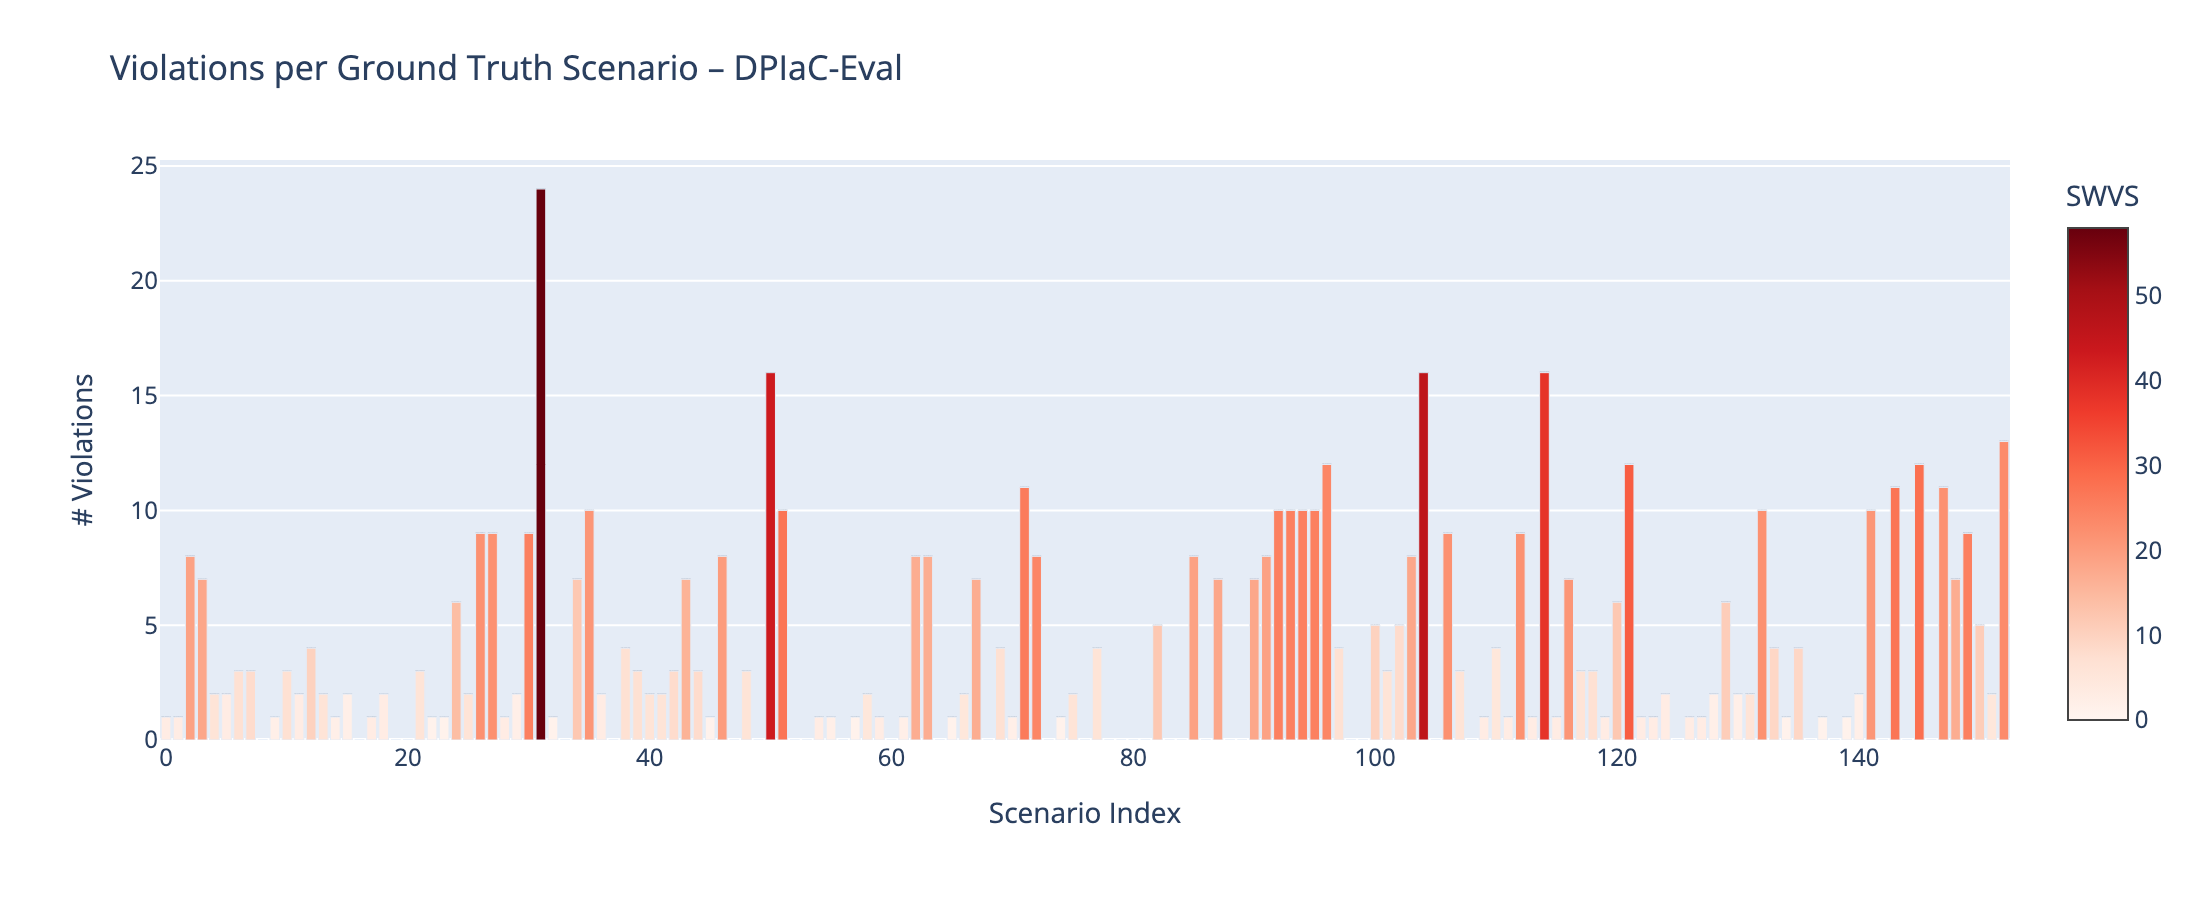

In [11]:
fig3 = go.Figure(go.Bar(
    x=df_result['row_number'],
    y=df_result['failed_checks'],
    marker_color=df_result['swvs'],
    marker_colorscale='Reds',
    marker_colorbar=dict(title='SWVS'),
    text=df_result['template'].str.replace('.yaml','',regex=False),
    hovertemplate=(
        '<b>%{text}</b><br>'
        'Violations: %{y}<br>'
        'SWVS: %{marker.color:.1f}<extra></extra>'
    ),
))
fig3.update_layout(
    title='Violations per Ground Truth Scenario – DPIaC-Eval',
    xaxis_title='Scenario Index', yaxis_title='# Violations',
    margin=dict(t=80, b=80), height=450,
)
fig3.show()

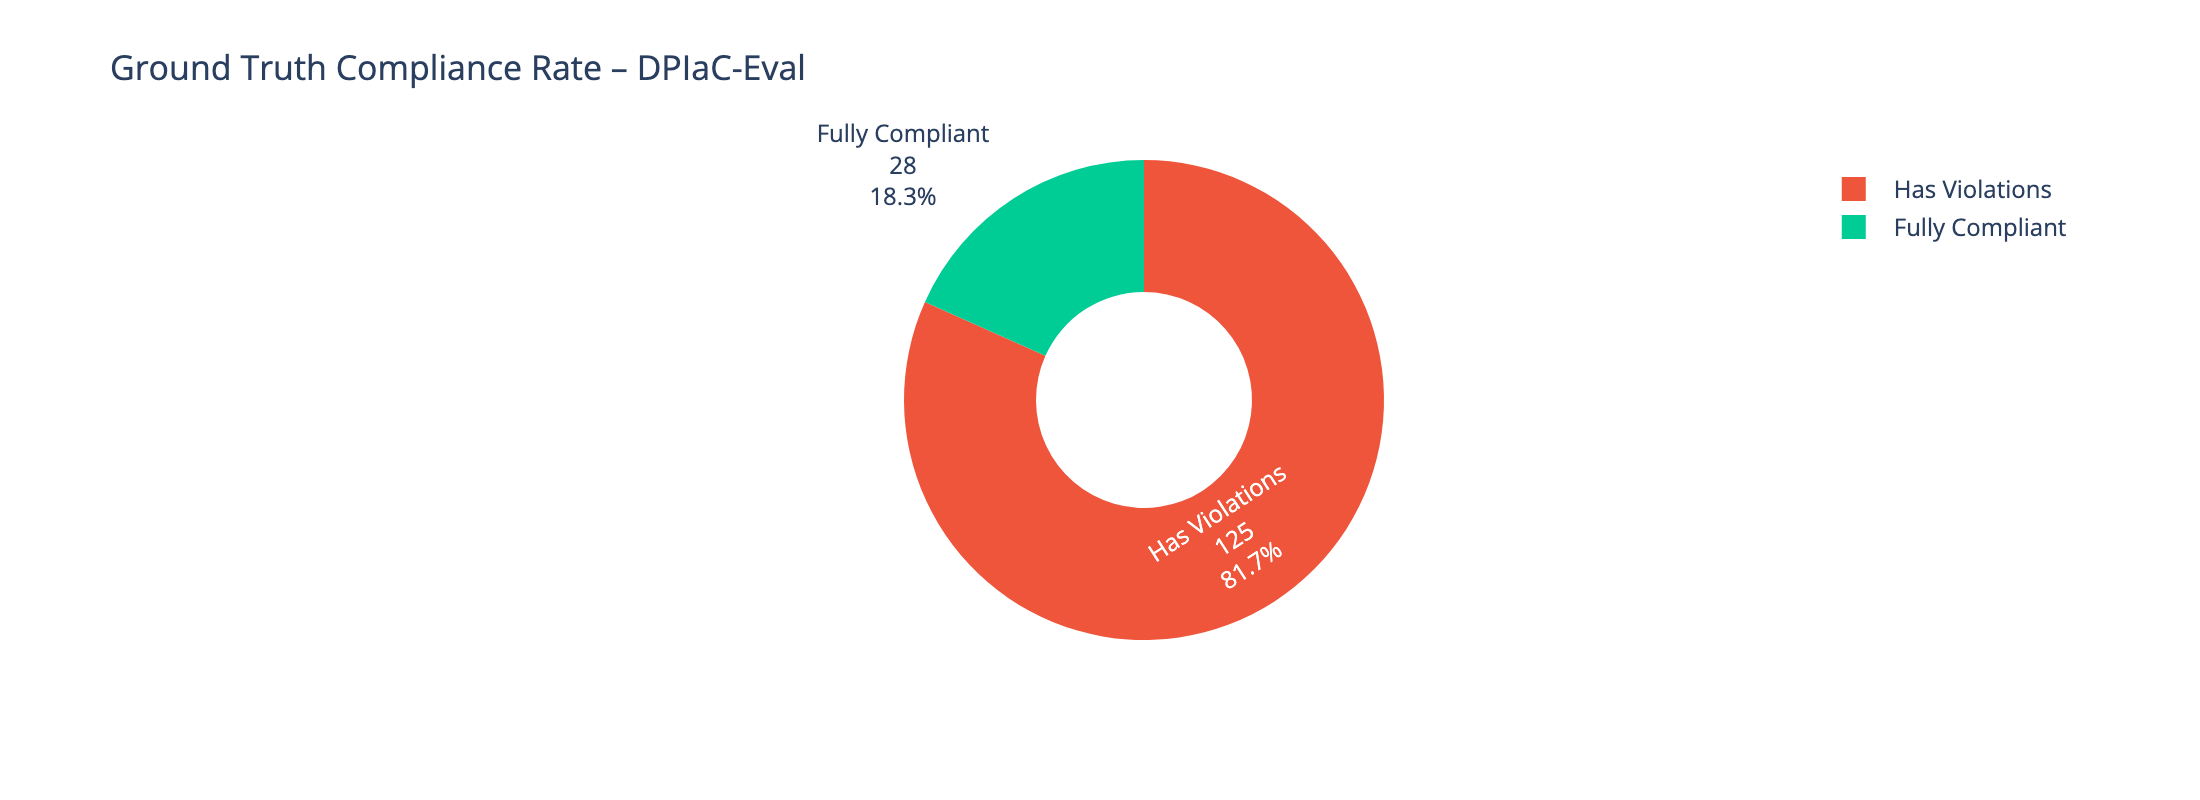

In [12]:
compliant_n   = int(df_result['fully_compliant'].sum())
noncompliant_n = len(df_result) - compliant_n

fig4 = go.Figure(go.Pie(
    labels=['Fully Compliant', 'Has Violations'],
    values=[compliant_n, noncompliant_n],
    marker_colors=['#00CC96', '#EF553B'],
    hole=0.45,
    textinfo='label+percent+value',
))
fig4.update_layout(
    title='Ground Truth Compliance Rate – DPIaC-Eval',
    margin=dict(t=80), height=400,
)
fig4.show()

In [13]:
save_df = df_result.copy()
for lc in ['violation_ids', 'violation_titles']:
    save_df[lc] = save_df[lc].apply(json.dumps)

save_df.to_csv(OUTPUT_DIR / 'dpiac_gt_trivy_full.csv', index=False)
save_df.to_parquet(OUTPUT_DIR / 'dpiac_gt_trivy_full.parquet')

print(f"All outputs saved → {OUTPUT_DIR}/")
print(f"  dpiac_gt_security_annotations.csv  ← per-scenario violation IDs")
print(f"  dpiac_gt_trivy_full.csv / .parquet  ← full numeric results")
print(f"  top20_violations.csv")
print(f"  fig1_top20_violations.png")
print(f"  fig2_severity_distribution.png")
print(f"  fig3_per_scenario_violations.png")
print(f"  fig4_compliance_pie.png")

All outputs saved → output/dpiac_security_audit/
  dpiac_gt_security_annotations.csv  ← per-scenario violation IDs
  dpiac_gt_trivy_full.csv / .parquet  ← full numeric results
  top20_violations.csv
  fig1_top20_violations.png
  fig2_severity_distribution.png
  fig3_per_scenario_violations.png
  fig4_compliance_pie.png


# cfn-lint

In [14]:
CFNLINT_TIMEOUT = 60

def run_cfnlint(template_path: Path) -> dict:
    result = dict(
        lint_pass=None, lint_errors=-1, lint_warnings=0, lint_info=0,
        lint_error_codes='', lint_error_msg='', lint_error=None,
    )
    try:
        proc = subprocess.run(
            ['cfn-lint', '--format', 'json', str(template_path)],
            capture_output=True, text=True, timeout=CFNLINT_TIMEOUT,
        )
    except subprocess.TimeoutExpired:
        result['lint_error'] = 'TimeoutExpired'
        return result
    except FileNotFoundError:
        result['lint_error'] = 'cfn-lint_not_found'
        return result
    except Exception as e:
        result['lint_error'] = str(e)
        return result

    try:
        matches = json.loads(proc.stdout) if proc.stdout.strip() else []
    except json.JSONDecodeError:
        result['lint_error'] = f'json_parse_failed: {proc.stdout[:200]}'
        return result

    errors   = [m for m in matches if m.get('Level') == 'Error']
    warnings = [m for m in matches if m.get('Level') == 'Warning']
    infos    = [m for m in matches if m.get('Level') == 'Informational']

    result['lint_pass']        = len(errors) == 0
    result['lint_errors']      = len(errors)
    result['lint_warnings']    = len(warnings)
    result['lint_info']        = len(infos)
    result['lint_error_codes'] = ' | '.join(sorted({m.get('Rule', {}).get('Id', '') for m in errors}))
    result['lint_error_msg']   = str(errors[0].get('Message', ''))[:300] if errors else ''
    return result

_sample_lint = run_cfnlint(TEMPLATE_ROOT / df['template_path'].iloc[0].name)
print(f"Sample lint result ({df['template_path'].iloc[0].name}): pass={_sample_lint['lint_pass']}, "
      f"errors={_sample_lint['lint_errors']}, warnings={_sample_lint['lint_warnings']}")

Sample lint result (sqs_easy.yaml): pass=True, errors=0, warnings=0


In [15]:
df_lint = resumable_scan(
    df, 'row_number',
    lambda row: run_cfnlint(row['template_path']),
    CFNLINT_CACHE_PATH, 'cfn-lint scan',
)
df_lint = df[['row_number']].merge(df_lint, on='row_number', how='left')

n_tool_errors = df_lint['lint_error'].notna().sum()
print(f"\ncfn-lint scan complete")
print(f"  Scenarios scanned : {len(df_lint):,}")
print(f"  Lint pass         : {int(df_lint['lint_pass'].sum()):,}  ({df_lint['lint_pass'].mean()*100:.1f}%)")
print(f"  Tool errors        : {n_tool_errors:,}")
df_lint[['row_number','lint_pass','lint_errors','lint_warnings','lint_error_codes']].head(10)

📂 cfn-lint scan: 153 cached, 0 to scan


cfn-lint scan: 0template [00:00, ?template/s]


cfn-lint scan complete
  Scenarios scanned : 153
  Lint pass         : 125  (81.7%)
  Tool errors        : 0


,row_number,lint_pass,lint_errors,lint_warnings,lint_error_codes
0,0,True,0,0,NaN
1,1,True,0,0,NaN
2,2,True,0,0,NaN
3,3,True,0,0,NaN
4,4,True,0,0,NaN
5,5,True,0,0,NaN
6,6,True,0,0,NaN
7,7,True,0,1,NaN
8,8,True,0,0,NaN
9,9,True,0,0,NaN


# Checkov

In [16]:
def run_checkov_cfn(template_path: Path, timeout: int = 120) -> dict:
    result = dict(
        checkov_passed=False, checkov_error=None,
        total_checks=0, passed_checks=0, failed_checks=0,
        policy_pass_rate=None, fully_compliant=False,
        severity_critical=0, severity_high=0, severity_medium=0,
        severity_low=0, severity_unknown=0,
        violations=[], violation_ids=[], violation_titles=[],
    )

    if not template_path.exists():
        result['checkov_error'] = f'file_not_found: {template_path}'
        return result

    cmd = [
        'checkov',
        '--file',      str(template_path),
        '--framework', 'cloudformation',
        '--output',    'json',
        '--quiet',
        '--soft-fail',
    ]

    try:
        proc = subprocess.run(
            cmd, capture_output=True, text=True, timeout=timeout
        )
    except subprocess.TimeoutExpired:
        result['checkov_error'] = 'TimeoutExpired'; return result
    except FileNotFoundError:
        result['checkov_error'] = 'checkov_not_found'; return result
    except Exception as e:
        result['checkov_error'] = str(e); return result

    stdout = proc.stdout.strip()
    json_start = re.search(r'[\[\{]', stdout)
    if not json_start:
        result['checkov_error'] = f'no_json: {stdout[:200]}'
        return result

    try:
        raw = json.loads(stdout[json_start.start():])
    except json.JSONDecodeError as e:
        result['checkov_error'] = f'json_parse_failed: {e}'
        return result

    blocks = raw if isinstance(raw, list) else [raw]

    for block in blocks:
        summary = block.get('summary', {})
        results = block.get('results', {})

        result['passed_checks'] += int(summary.get('passed', 0))
        result['failed_checks'] += int(summary.get('failed', 0))

        for check in results.get('failed_checks', []):
            check_id    = check.get('check_id', '')
            check_title = check.get('check_name', check_id)
            sev         = (check.get('severity') or 'UNKNOWN').upper()
            resource    = check.get('resource', '')
            resource_type = resource.split('.')[0] if '.' in resource else resource

            result['violations'].append({
                'check_id':      check_id,
                'check_title':   check_title,
                'resource':      resource,
                'resource_type': resource_type,
                'severity':      sev,
                'file':          check.get('file_path', str(template_path)),
                'lines':         check.get('file_line_range', []),
                'description':   check.get('description', ''),
                'guideline':     check.get('guideline', ''),
            })
            result['violation_ids'].append(check_id)
            result['violation_titles'].append(check_title)

            sev_col = {
                'CRITICAL': 'severity_critical', 'HIGH': 'severity_high',
                'MEDIUM':   'severity_medium',   'LOW':  'severity_low',
            }.get(sev, 'severity_unknown')
            result[sev_col] += 1

    result['total_checks'] = result['passed_checks'] + result['failed_checks']
    if result['total_checks'] > 0:
        result['policy_pass_rate'] = round(
            result['passed_checks'] / result['total_checks'], 4
        )
    result['fully_compliant'] = (
        result['total_checks'] > 0 and result['failed_checks'] == 0
    )
    result['checkov_passed'] = result['fully_compliant']
    return result

In [17]:
sample = run_checkov_cfn(TEMPLATE_ROOT / 'compliant-bucket.yaml')
print(f"passed : {sample['passed_checks']}")
print(f"failed : {sample['failed_checks']}")
print(f"PPR    : {sample['policy_pass_rate']}")
print(f"IDs    : {sample['violation_ids']}")

passed : 32
failed : 0
PPR    : 1.0
IDs    : []


In [18]:
df_ckv_raw = resumable_scan(
    df, 'row_number',
    lambda row: run_checkov_cfn(Path(row['template_path'])),
    CHECKOV_CACHE_PATH, 'Checkov CFn scan',
)
df_ckv_raw = df[['row_number']].merge(df_ckv_raw, on='row_number', how='left')
df_ckv_raw['checkov_scanned'] = df_ckv_raw['total_checks'] > 0

CKV_SCALAR_COLS = [
    'checkov_passed', 'checkov_error',
    'total_checks', 'passed_checks', 'failed_checks',
    'policy_pass_rate', 'fully_compliant',
    'severity_critical', 'severity_high', 'severity_medium',
    'severity_low', 'severity_unknown', 'checkov_scanned',
]

df_checkov = df_result[['row_number', 'template', 'prompt']].copy()
for c in CKV_SCALAR_COLS:
    df_checkov[c] = df_ckv_raw[c]
df_checkov['violation_ids']    = df_ckv_raw['violation_ids']
df_checkov['violation_titles'] = df_ckv_raw['violation_titles']
df_checkov['violations_json']  = df_ckv_raw['violations'].apply(json.dumps)

df_checkov['swvs'] = (
    df_checkov['severity_critical'] * 4 + df_checkov['severity_high']     * 3 +
    df_checkov['severity_medium']   * 2 + df_checkov['severity_low']      * 1 +
    df_checkov['severity_unknown']  * 0.5
)

errors = df_checkov[df_checkov['checkov_error'].notna()]
print(f"\nCheckov scan complete")
print(f"  Scenarios scanned     : {len(df_checkov):,}")
print(f"  Scan errors           : {len(errors):,}")
print(f"  Fully compliant (FCR) : {df_checkov['fully_compliant'].sum():,}  "
      f"({df_checkov['fully_compliant'].mean()*100:.1f}%)")
print(f"  Mean PPR              : {df_checkov['policy_pass_rate'].mean()*100:.1f}%")
print(f"  Total violations      : {df_checkov['failed_checks'].sum():,}")
print(f"  Note: open-source Checkov never populates a 'severity' field on failed")
print(f"  checks (verified empirically) — severity_* columns above are schema-only.")
df_checkov.head()

📂 Checkov CFn scan: 153 cached, 0 to scan


Checkov CFn scan: 0template [00:00, ?template/s]


Checkov scan complete
  Scenarios scanned     : 153
  Scan errors           : 0
  Fully compliant (FCR) : 19  (12.4%)
  Mean PPR              : 63.5%
  Total violations      : 504
  Note: open-source Checkov never populates a 'severity' field on failed
  checks (verified empirically) — severity_* columns above are schema-only.


,row_number,template,prompt,checkov_passed,checkov_error,total_checks,passed_checks,failed_checks,policy_pass_rate,fully_compliant,severity_critical,severity_high,severity_medium,severity_low,severity_unknown,checkov_scanned,violation_ids,violation_titles,violations_json,swvs
0,0,Data\groud_truth\template\sqs_easy.yaml,We need a CloudFormation template that creates...,False,NaN,1,0,1,0.0000,False,0,0,0,0,1,True,[CKV_AWS_27],[Ensure all data stored in the SQS queue is en...,"[{""check_id"": ""CKV_AWS_27"", ""check_title"": ""En...",0.5
1,1,Data\groud_truth\template\sns_easy.yaml,We need a CloudFormation template that creates...,False,NaN,1,0,1,0.0000,False,0,0,0,0,1,True,[CKV_AWS_26],[Ensure all data stored in the SNS topic is en...,"[{""check_id"": ""CKV_AWS_26"", ""check_title"": ""En...",0.5
2,2,Data\groud_truth\template\s3_easy.yaml,We need a CloudFormation template that creates...,False,NaN,9,3,6,0.3333,False,0,0,0,0,6,True,"[CKV_AWS_18, CKV_AWS_53, CKV_AWS_54, CKV_AWS_2...",[Ensure the S3 bucket has access logging enabl...,"[{""check_id"": ""CKV_AWS_18"", ""check_title"": ""En...",3.0
3,3,Data\groud_truth\template\s3_webhost_and_delet...,We need a CloudFormation template that creates...,False,NaN,9,3,6,0.3333,False,0,0,0,0,6,True,"[CKV_AWS_18, CKV_AWS_53, CKV_AWS_54, CKV_AWS_2...",[Ensure the S3 bucket has access logging enabl...,"[{""check_id"": ""CKV_AWS_18"", ""check_title"": ""En...",3.0
4,4,Data\groud_truth\template\ec2_easy.yaml,We need a CloudFormation template that creates...,True,NaN,2,2,0,1.0000,True,0,0,0,0,0,True,[],[],[],0.0


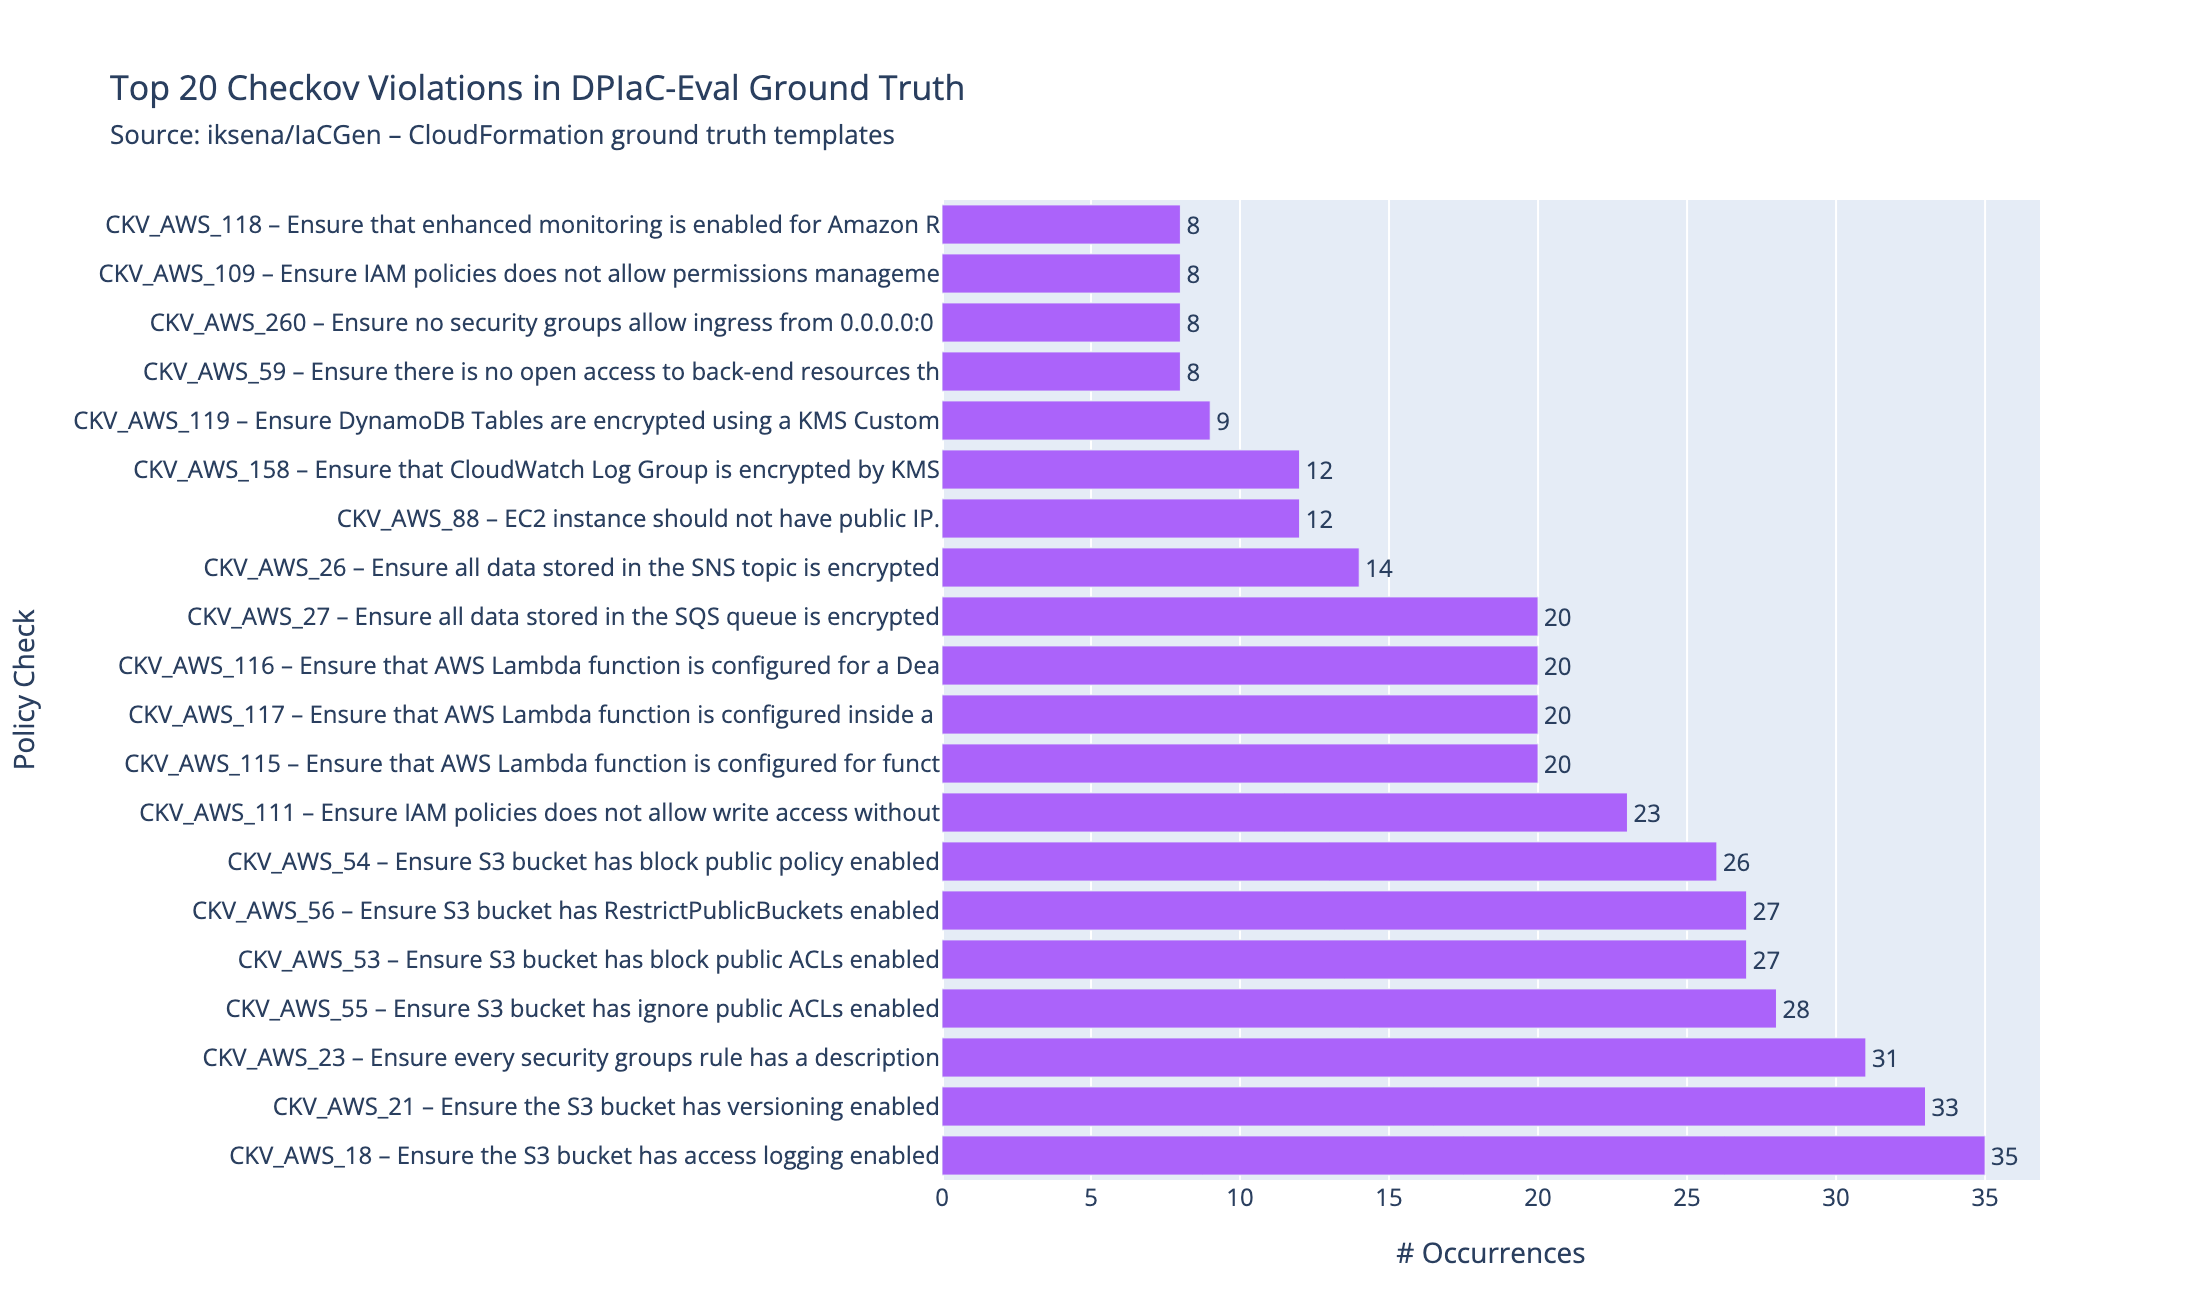

In [19]:
all_ckv_viols = []
for vj in df_checkov['violations_json']:
    try: all_ckv_viols.extend(json.loads(vj))
    except: pass

df_ckv_viol = pd.DataFrame(all_ckv_viols)

ckv_top20 = (
    df_ckv_viol.groupby(['check_id', 'check_title'])
    .size().reset_index(name='count')
    .sort_values('count', ascending=False)
).head(20)

ckv_top20['label'] = ckv_top20.apply(
    lambda r: f"{r['check_id']} – {str(r['check_title'])[:55]}", axis=1
)

fig_ckv1 = go.Figure(go.Bar(
    x=ckv_top20['count'],
    y=ckv_top20['label'],
    orientation='h',
    text=ckv_top20['count'],
    textposition='outside',
    cliponaxis=False,
    marker_color='#AB63FA',
))
fig_ckv1.update_layout(
    title="Top 20 Checkov Violations in DPIaC-Eval Ground Truth<br>"
          "<span style='font-size:13px;font-weight:normal;'>"
          "Source: iksena/IaCGen – CloudFormation ground truth templates</span>",
    xaxis_title='# Occurrences',
    yaxis_title='Policy Check',
    margin=dict(l=440, r=80, t=100, b=60),
    height=650,
)
fig_ckv1.show()
ckv_top20.to_csv(OUTPUT_DIR / 'checkov_top20_violations.csv', index=False)

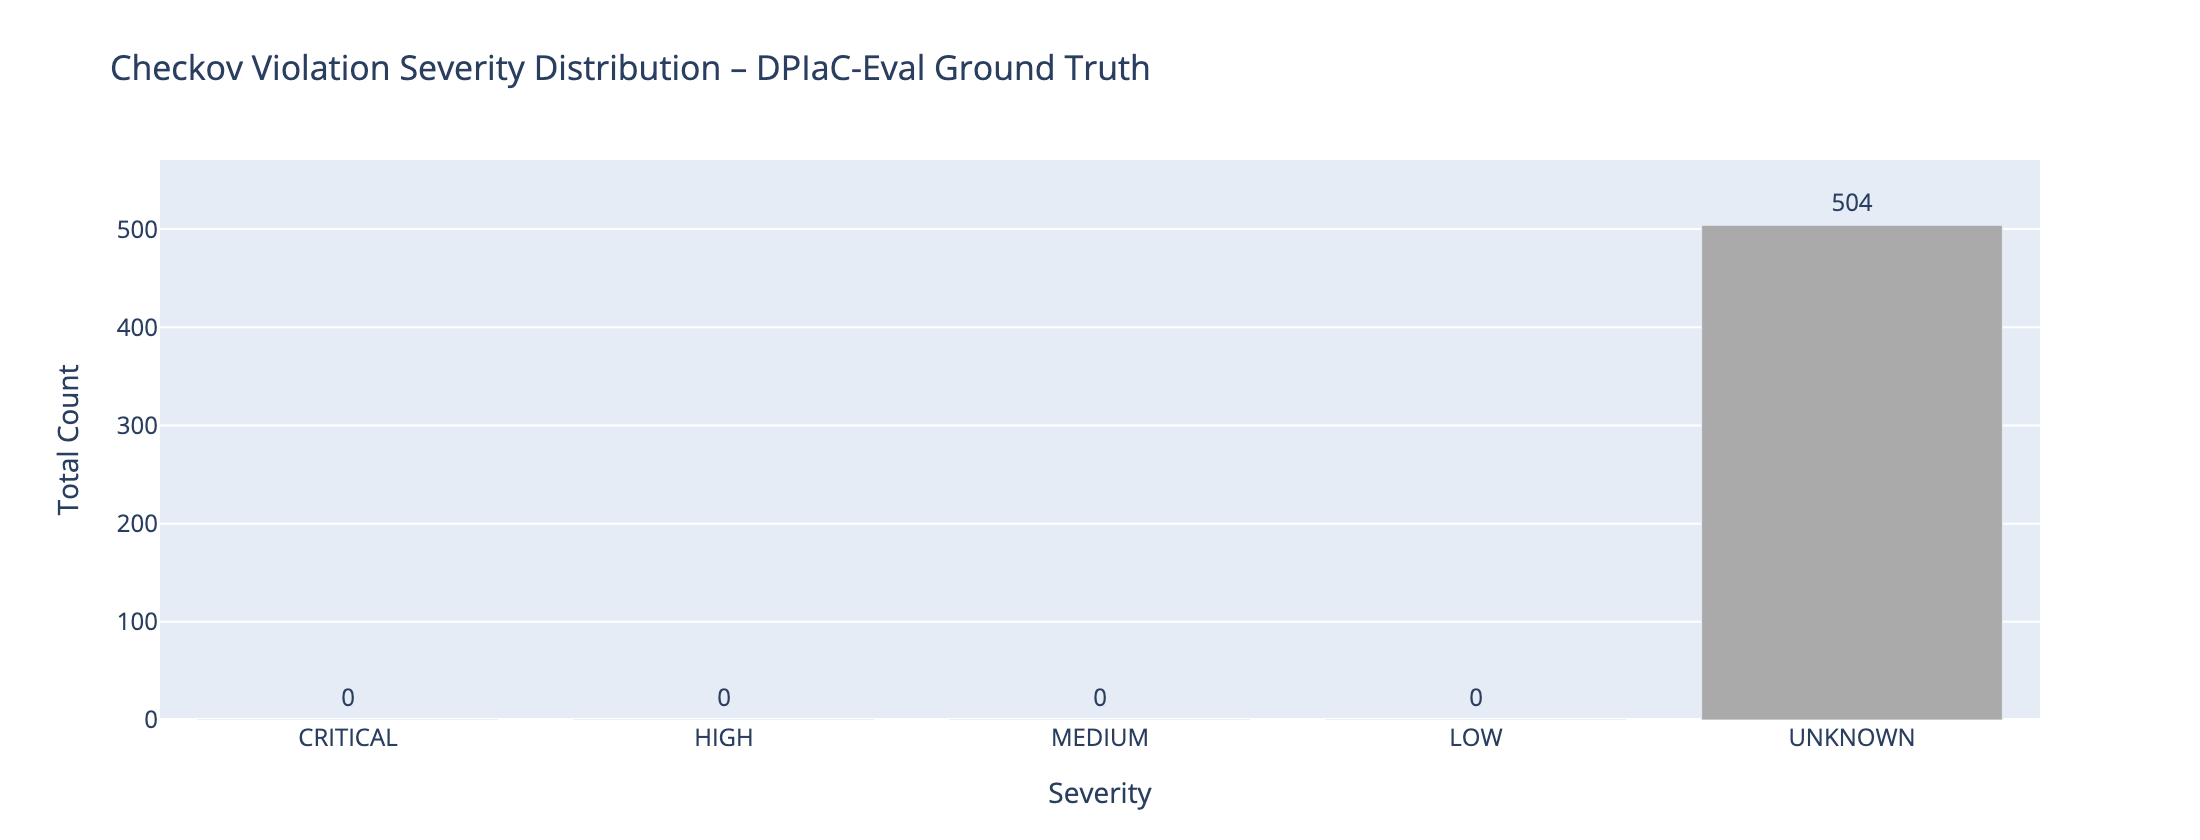

In [20]:
ckv_sev = {s: int(df_checkov[c].sum()) for s, c in [
    ('CRITICAL','severity_critical'), ('HIGH','severity_high'),
    ('MEDIUM','severity_medium'),     ('LOW','severity_low'),
    ('UNKNOWN','severity_unknown'),
]}

fig_ckv2 = go.Figure(go.Bar(
    x=list(ckv_sev.keys()),
    y=list(ckv_sev.values()),
    marker_color=[SEV_COLORS[s] for s in ckv_sev],
    text=list(ckv_sev.values()),
    textposition='outside',
))
fig_ckv2.update_layout(
    title='Checkov Violation Severity Distribution – DPIaC-Eval Ground Truth',
    xaxis_title='Severity', yaxis_title='Total Count',
    margin=dict(t=80, b=60), height=420,
)
fig_ckv2.show()

                    Metric Trivy Checkov
   FCR (% fully compliant) 18.3%   12.4%
              Mean PPR (%) 90.2%   63.5%
          Total violations   584     504
Mean violations / scenario   3.8     3.3
                  CRITICAL    24       0
                      HIGH   295       0
                    MEDIUM   106       0
                       LOW   159       0


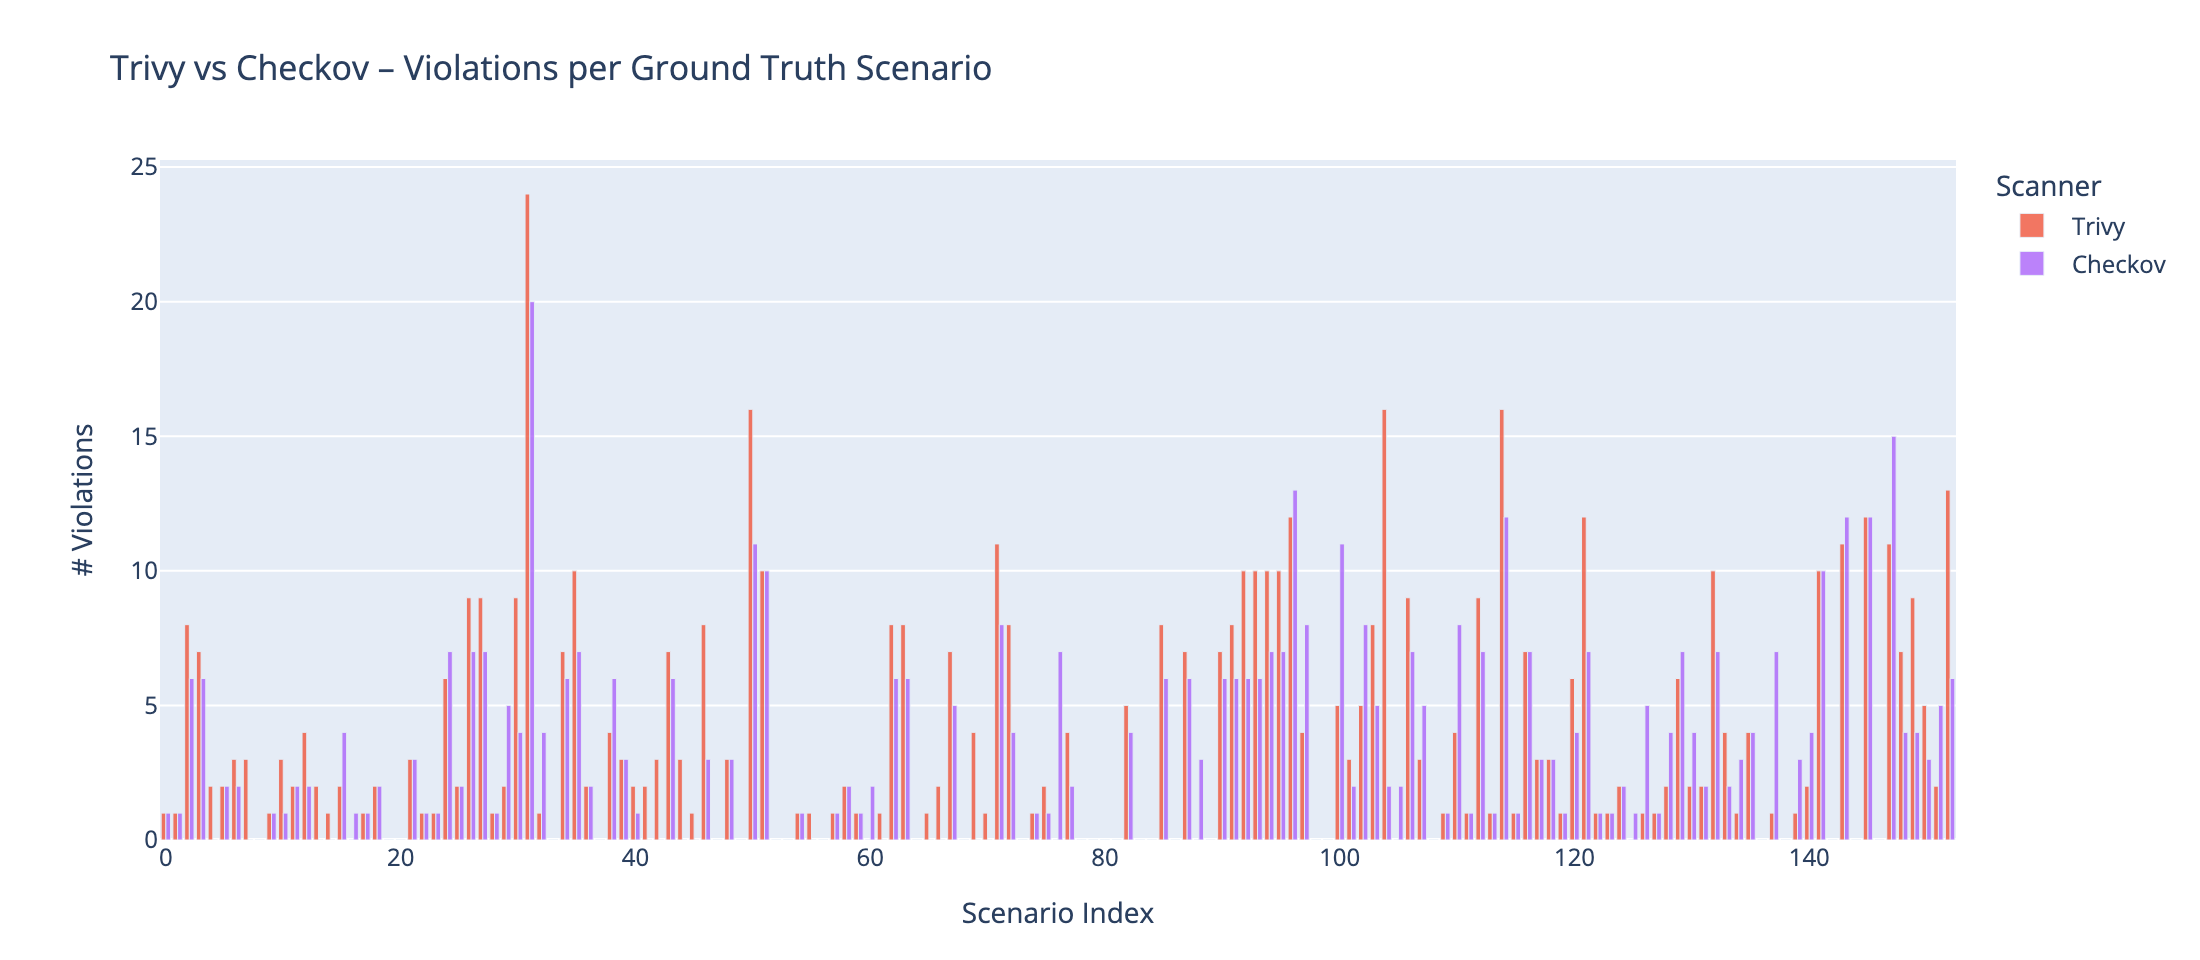

In [21]:
compare_df = pd.DataFrame({
    'Metric': [
        'FCR (% fully compliant)', 'Mean PPR (%)',
        'Total violations', 'Mean violations / scenario',
        'CRITICAL', 'HIGH', 'MEDIUM', 'LOW',
    ],
    'Trivy': [
        f"{df_result['fully_compliant'].mean()*100:.1f}%",
        f"{df_result['policy_pass_rate'].mean()*100:.1f}%",
        f"{df_result['failed_checks'].sum():,}",
        f"{df_result['failed_checks'].mean():.1f}",
        f"{df_result['severity_critical'].sum():,}",
        f"{df_result['severity_high'].sum():,}",
        f"{df_result['severity_medium'].sum():,}",
        f"{df_result['severity_low'].sum():,}",
    ],
    'Checkov': [
        f"{df_checkov['fully_compliant'].mean()*100:.1f}%",
        f"{df_checkov['policy_pass_rate'].mean()*100:.1f}%",
        f"{df_checkov['failed_checks'].sum():,}",
        f"{df_checkov['failed_checks'].mean():.1f}",
        f"{df_checkov['severity_critical'].sum():,}",
        f"{df_checkov['severity_high'].sum():,}",
        f"{df_checkov['severity_medium'].sum():,}",
        f"{df_checkov['severity_low'].sum():,}",
    ],
})
print(compare_df.to_string(index=False))

fig_cmp = go.Figure()
for scanner, df_s, color in [
    ('Trivy',   df_result,  '#EF553B'),
    ('Checkov', df_checkov, '#AB63FA'),
]:
    fig_cmp.add_trace(go.Bar(
        name=scanner,
        x=df_s['row_number'],
        y=df_s['failed_checks'],
        marker_color=color,
        opacity=0.8,
        hovertemplate=f'<b>{scanner}</b><br>Scenario: %{{x}}<br>Violations: %{{y}}<extra></extra>',
    ))

fig_cmp.update_layout(
    title='Trivy vs Checkov – Violations per Ground Truth Scenario',
    xaxis_title='Scenario Index',
    yaxis_title='# Violations',
    barmode='group',
    legend_title='Scanner',
    margin=dict(t=80, b=60),
    height=480,
)
fig_cmp.show()

In [22]:
df_combined = df_result[['row_number','template','prompt',
                          'failed_checks','policy_pass_rate','fully_compliant']].copy()
df_combined.rename(columns={
    'failed_checks':    'trivy_violations',
    'policy_pass_rate': 'trivy_ppr',
    'fully_compliant':  'trivy_compliant',
}, inplace=True)

df_combined['trivy_violation_ids'] = df_result['violation_ids'].apply(
    lambda ids: ' | '.join(sorted(set(ids))) if ids else '✅ NONE'
)

df_combined['checkov_violations']    = df_checkov['failed_checks']
df_combined['checkov_ppr']           = df_checkov['policy_pass_rate']
df_combined['checkov_compliant']     = df_checkov['fully_compliant']
df_combined['checkov_violation_ids'] = df_checkov['violation_ids'].apply(
    lambda ids: ' | '.join(sorted(set(ids))) if ids else '✅ NONE'
)

def _union_ids(row):
    t = set(row['trivy_violation_ids'].split(' | ')) if row['trivy_violation_ids'] != '✅ NONE' else set()
    c = set(row['checkov_violation_ids'].split(' | ')) if row['checkov_violation_ids'] != '✅ NONE' else set()
    combined = sorted(t | c)
    return ' | '.join(combined) if combined else '✅ NONE'

df_combined['all_violation_ids'] = df_combined.apply(_union_ids, axis=1)
df_combined['any_violation']     = df_combined['all_violation_ids'] != '✅ NONE'

df_combined['lint_pass']   = df_lint['lint_pass']
df_combined['lint_errors'] = df_lint['lint_errors']
df_combined['trivy_not_scanned']   = df_result['trivy_error'] == 'not_scanned_by_trivy'
df_combined['checkov_not_scanned'] = ~df_checkov['checkov_scanned']

df_combined['trivy_ppr_pct']   = (df_combined['trivy_ppr']   * 100).round(1)
df_combined['checkov_ppr_pct'] = (df_combined['checkov_ppr'] * 100).round(1)

df_combined.drop(columns=['trivy_ppr','checkov_ppr']).to_csv(
    OUTPUT_DIR / 'dpiac_gt_combined_annotations.csv', index=False
)
print(f"Saved → dpiac_gt_combined_annotations.csv")
print(f"  Scenarios with ANY violation: {df_combined['any_violation'].sum()} / {len(df_combined)}")
print(f"\nSample:")
print(df_combined[['row_number','template','trivy_violation_ids','checkov_violation_ids']]
      .head(10).to_string(index=False))

Saved → dpiac_gt_combined_annotations.csv
  Scenarios with ANY violation: 124 / 153

Sample:
 row_number                                                          template                                                                   trivy_violation_ids                                                       checkov_violation_ids
          0                           Data\groud_truth\template\sqs_easy.yaml                                                                              AWS-0096                                                                  CKV_AWS_27
          1                           Data\groud_truth\template\sns_easy.yaml                                                                              AWS-0095                                                                  CKV_AWS_26
          2                            Data\groud_truth\template\s3_easy.yaml AWS-0086 | AWS-0087 | AWS-0089 | AWS-0090 | AWS-0091 | AWS-0093 | AWS-0094 | AWS-0132 CKV_AWS_18 | CKV_AWS_21

In [23]:
save_ckv = df_checkov.copy()
for lc in ['violation_ids', 'violation_titles']:
    save_ckv[lc] = save_ckv[lc].apply(json.dumps)
save_ckv.to_csv(OUTPUT_DIR / 'dpiac_gt_checkov_full.csv', index=False)
save_ckv.to_parquet(OUTPUT_DIR / 'dpiac_gt_checkov_full.parquet')

print(f"\nAll outputs saved → {OUTPUT_DIR}/")
print(f"  dpiac_gt_combined_annotations.csv   ← PRIMARY: both scanners, per scenario")
print(f"  dpiac_gt_checkov_full.csv / .parquet")
print(f"  checkov_top20_violations.csv")
print(f"  fig5_checkov_top20.png")
print(f"  fig6_checkov_severity.png")
print(f"  fig7_trivy_vs_checkov.png")


All outputs saved → output/dpiac_security_audit/
  dpiac_gt_combined_annotations.csv   ← PRIMARY: both scanners, per scenario
  dpiac_gt_checkov_full.csv / .parquet
  checkov_top20_violations.csv
  fig5_checkov_top20.png
  fig6_checkov_severity.png
  fig7_trivy_vs_checkov.png


# Extended Security Analytics

=== Checks processed vs passed, DPIaC-Eval ground truth (153 scenarios) ===
   tool  n_scenarios  checks_processed  checks_passed  checks_failed  severity_critical  severity_high  severity_medium  severity_low  severity_unknown  pass_rate_pct
  Trivy          153              5096           4512            584                 24            295              106           159                 0           88.5
Checkov          153              1978           1474            504                  0              0                0             0               504           74.5

Saved → output/dpiac_security_audit/checks_processed_by_severity.csv


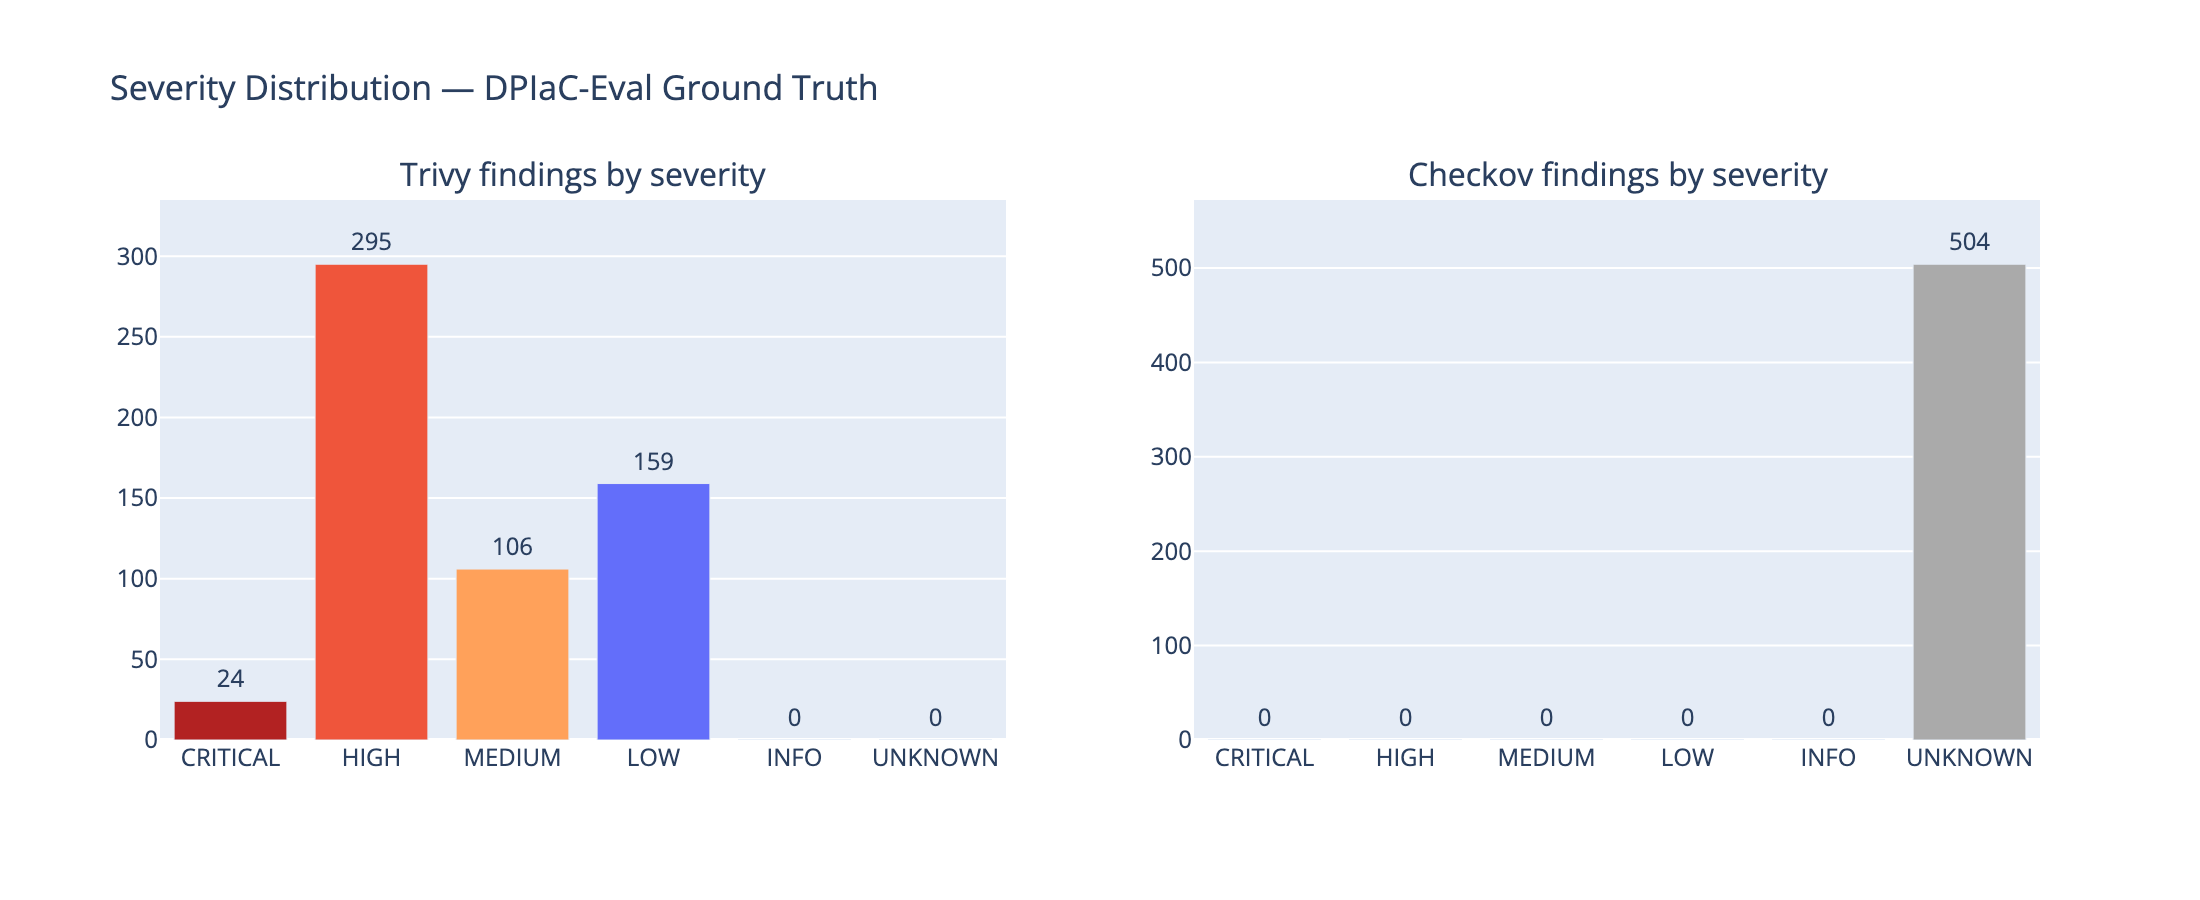

In [24]:
def _severity_totals(df_scan: pd.DataFrame, sev_cols: list) -> dict:
    return {c: int(df_scan[c].sum()) for c in sev_cols if c in df_scan.columns}

trivy_sev_cols = ['severity_critical', 'severity_high', 'severity_medium', 'severity_low', 'severity_unknown']
ckv_sev_cols   = ['severity_critical', 'severity_high', 'severity_medium', 'severity_low', 'severity_info', 'severity_unknown']

checks_summary = pd.DataFrame([
    {
        'tool': 'Trivy',
        'n_scenarios': len(df_result),
        'checks_processed': int(df_result['total_checks'].sum()),
        'checks_passed': int(df_result['passed_checks'].sum()),
        'checks_failed': int(df_result['failed_checks'].sum()),
        **_severity_totals(df_result, trivy_sev_cols),
    },
    {
        'tool': 'Checkov',
        'n_scenarios': len(df_checkov),
        'checks_processed': int(df_checkov['total_checks'].sum()),
        'checks_passed': int(df_checkov['passed_checks'].sum()),
        'checks_failed': int(df_checkov['failed_checks'].sum()),
        **_severity_totals(df_checkov, ckv_sev_cols),
    },
])
checks_summary['pass_rate_pct'] = (checks_summary['checks_passed'] / checks_summary['checks_processed'] * 100).round(1)

print("=== Checks processed vs passed, DPIaC-Eval ground truth (153 scenarios) ===")
print(checks_summary.fillna(0).to_string(index=False))
checks_summary.to_csv(OUTPUT_DIR / 'checks_processed_by_severity.csv', index=False)
print(f"\nSaved → {OUTPUT_DIR / 'checks_processed_by_severity.csv'}")

sev_labels_ext = ['CRITICAL', 'HIGH', 'MEDIUM', 'LOW', 'INFO', 'UNKNOWN']
fig_sev_both = make_subplots(rows=1, cols=2, subplot_titles=('Trivy findings by severity', 'Checkov findings by severity'))
for col_idx, tool_name in [(1, 'Trivy'), (2, 'Checkov')]:
    row = checks_summary[checks_summary['tool'] == tool_name].iloc[0]
    fig_sev_both.add_trace(go.Bar(
        x=sev_labels_ext,
        y=[row.get(f'severity_{s.lower()}', 0) or 0 for s in sev_labels_ext],
        marker_color=[SEV_COLORS.get(s, '#AAAAAA') for s in sev_labels_ext],
        text=[int(row.get(f'severity_{s.lower()}', 0) or 0) for s in sev_labels_ext],
        textposition='outside', showlegend=False,
    ), row=1, col=col_idx)
fig_sev_both.update_layout(title='Severity Distribution — DPIaC-Eval Ground Truth', height=450)
fig_sev_both.show()

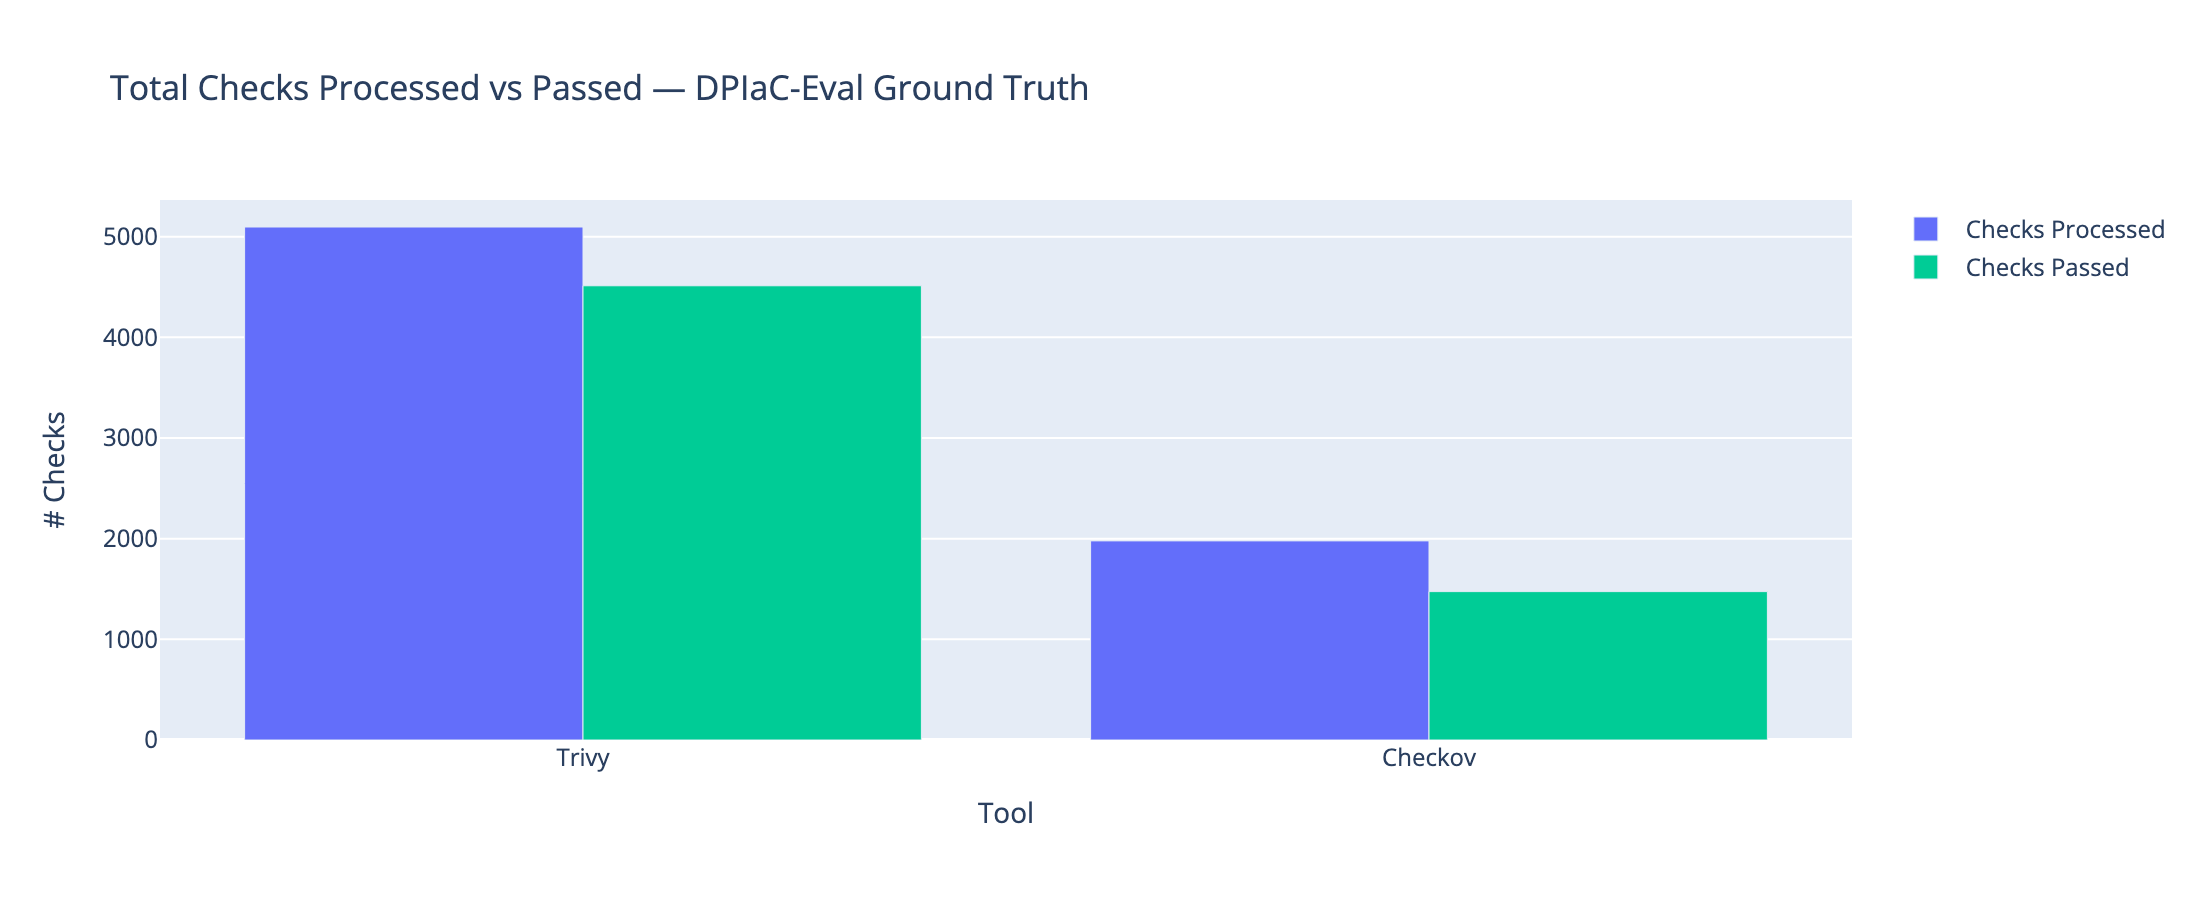

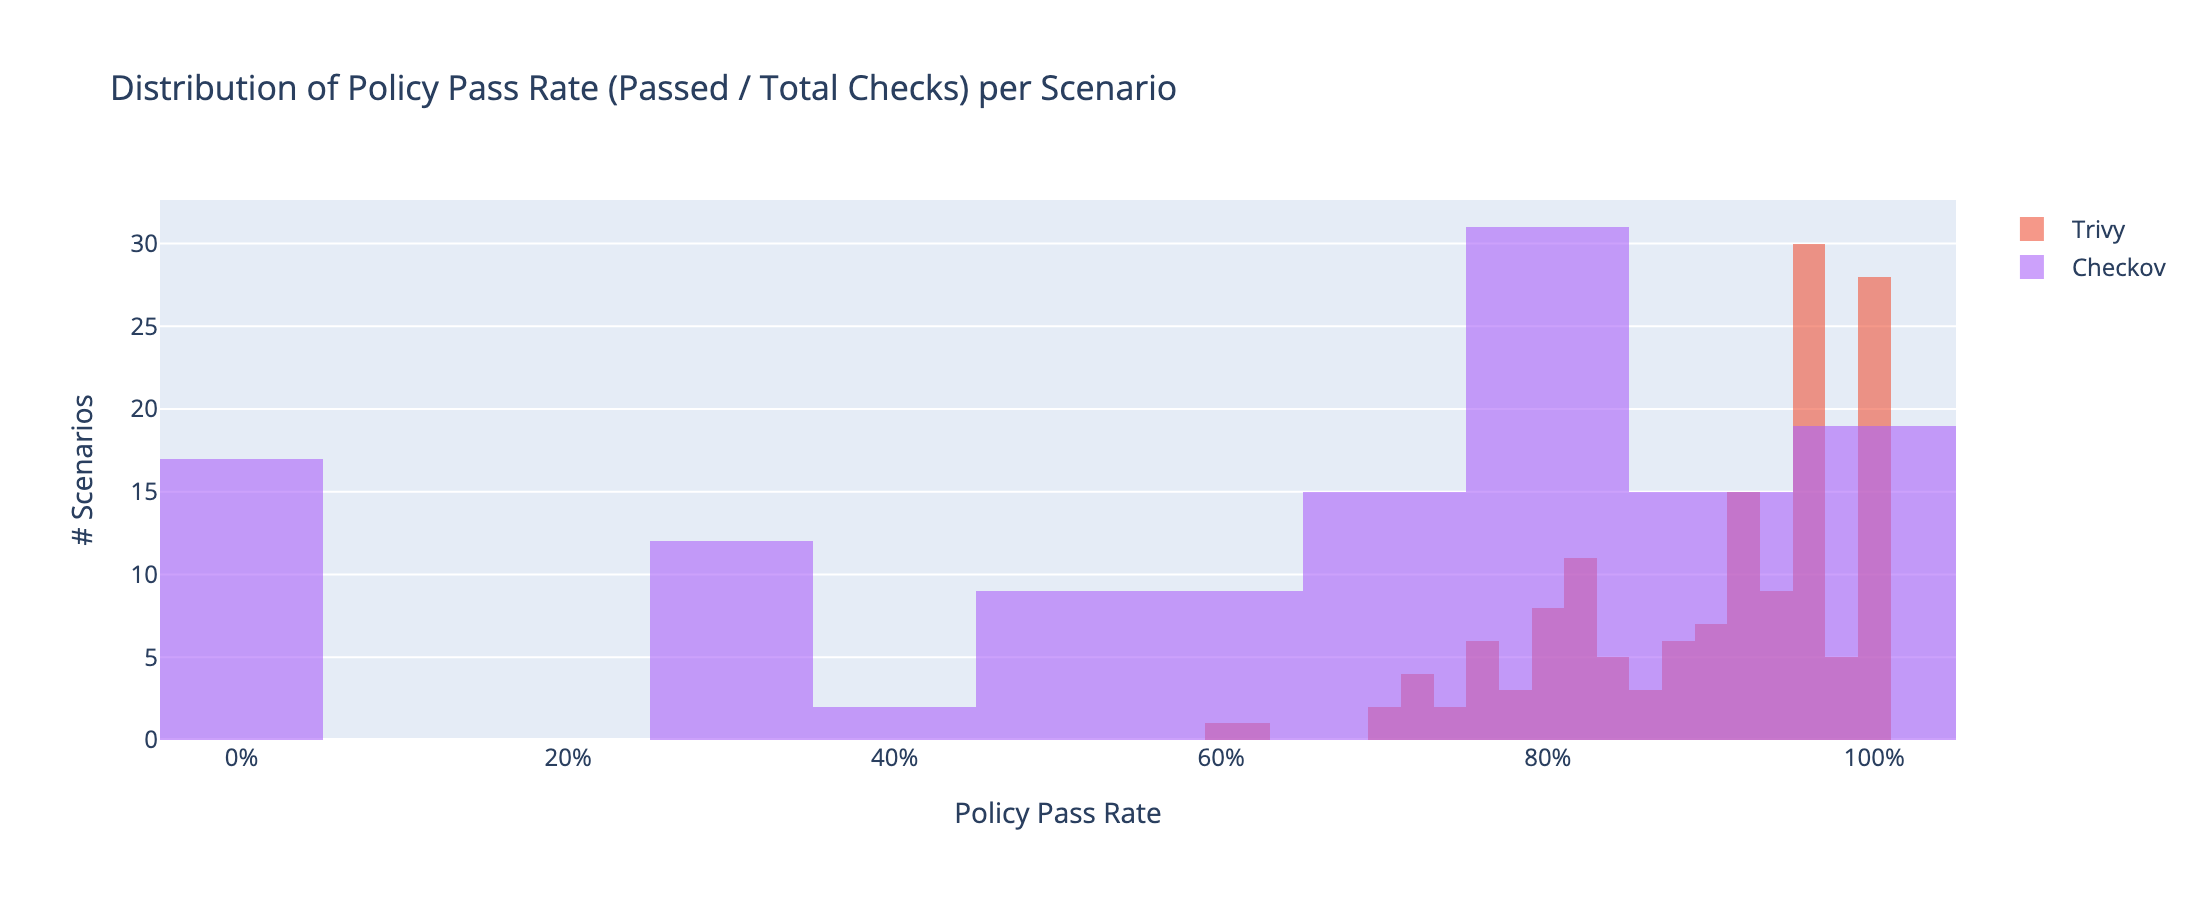

In [25]:
_checks_labels = checks_summary['tool']
fig_checks_bar = go.Figure()
fig_checks_bar.add_trace(go.Bar(name='Checks Processed', x=_checks_labels, y=checks_summary['checks_processed'], marker_color='#636EFA'))
fig_checks_bar.add_trace(go.Bar(name='Checks Passed', x=_checks_labels, y=checks_summary['checks_passed'], marker_color='#00CC96'))
fig_checks_bar.update_layout(
    barmode='group',
    title='Total Checks Processed vs Passed — DPIaC-Eval Ground Truth',
    xaxis_title='Tool', yaxis_title='# Checks', height=450,
)
fig_checks_bar.show()

_trivy_rates = df_result[df_result['total_checks'] > 0].copy()
_trivy_rates['pass_rate'] = _trivy_rates['passed_checks'] / _trivy_rates['total_checks']
_checkov_rates = df_checkov[df_checkov['total_checks'] > 0].copy()
_checkov_rates['pass_rate'] = _checkov_rates['passed_checks'] / _checkov_rates['total_checks']

fig_passrate_dist = go.Figure()
fig_passrate_dist.add_trace(go.Histogram(x=_trivy_rates['pass_rate'], name='Trivy', opacity=0.6, nbinsx=20, marker_color='#EF553B'))
fig_passrate_dist.add_trace(go.Histogram(x=_checkov_rates['pass_rate'], name='Checkov', opacity=0.6, nbinsx=20, marker_color='#AB63FA'))
fig_passrate_dist.update_layout(
    barmode='overlay',
    title='Distribution of Policy Pass Rate (Passed / Total Checks) per Scenario',
    xaxis_title='Policy Pass Rate', yaxis_title='# Scenarios',
    xaxis_tickformat='.0%', height=450,
)
fig_passrate_dist.show()

cfn-lint validity rate: 125/153 (81.7%)


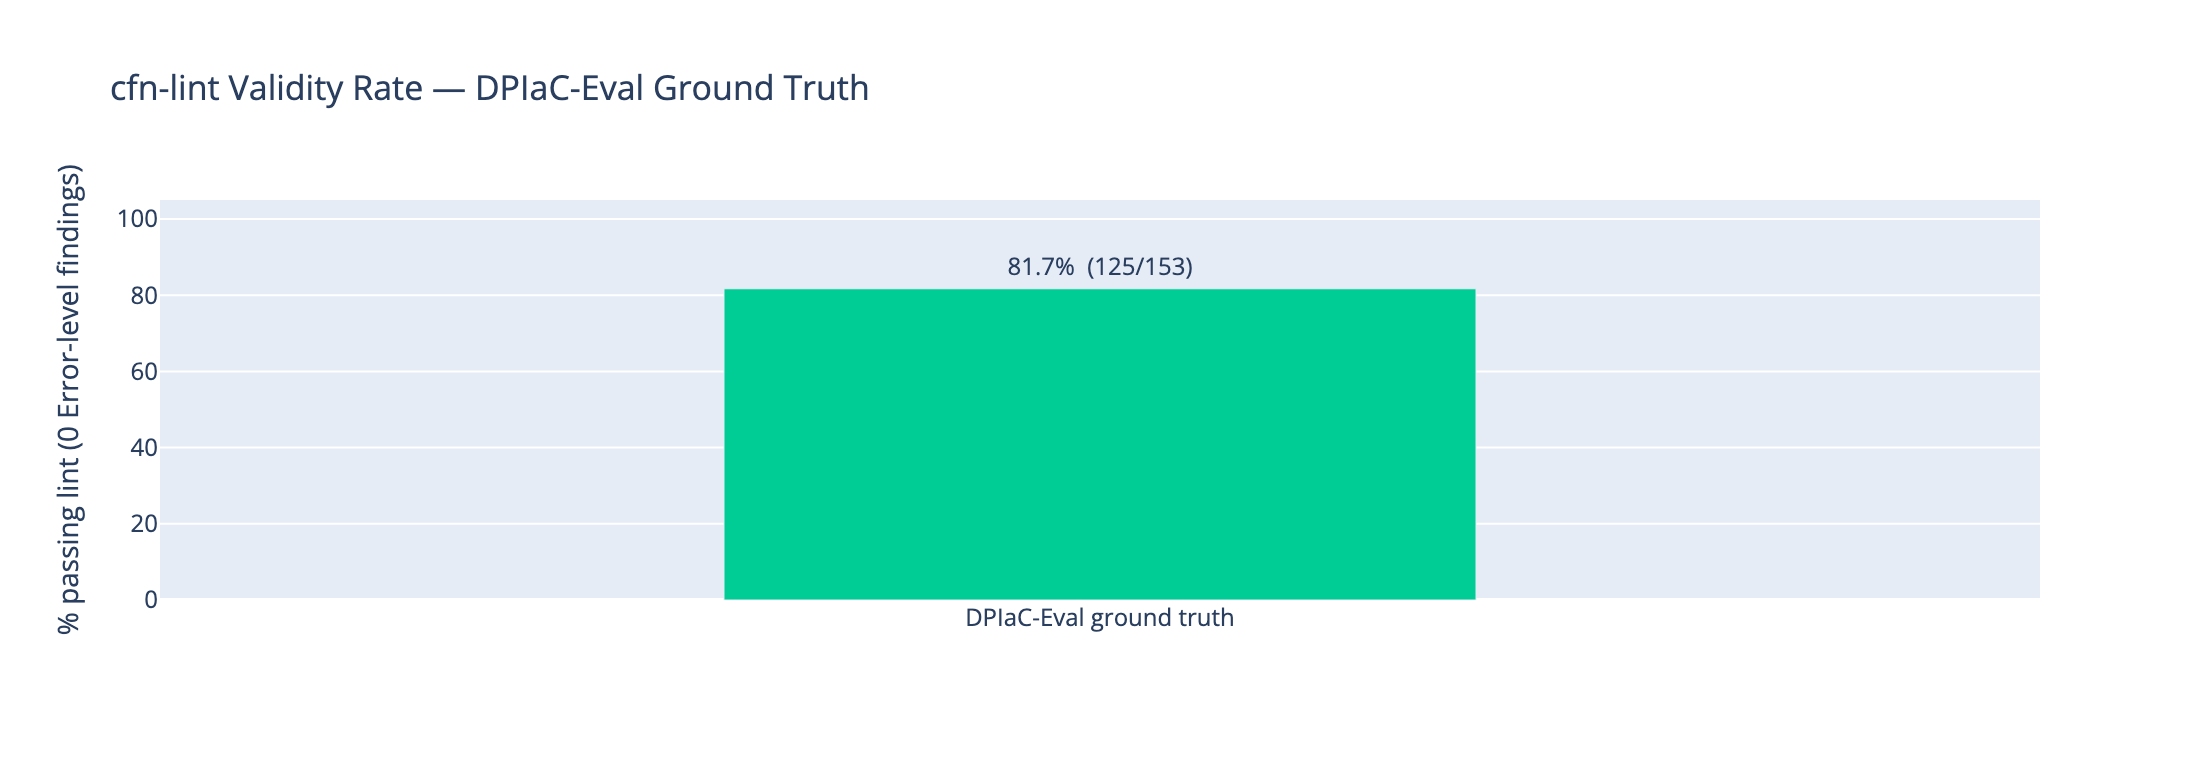

In [26]:
lint_pass_n = int(df_lint['lint_pass'].sum())
lint_pass_pct = round(pd.to_numeric(df_lint['lint_pass'], errors='coerce').mean() * 100, 1)
print(f"cfn-lint validity rate: {lint_pass_n}/{len(df_lint)} ({lint_pass_pct}%)")

fig_lint_dpiac = go.Figure(go.Bar(
    x=['DPIaC-Eval ground truth'], y=[lint_pass_pct],
    text=[f'{lint_pass_pct}%  ({lint_pass_n}/{len(df_lint)})'], textposition='outside',
    marker_color='#00CC96', width=[0.4],
))
fig_lint_dpiac.update_layout(
    title='cfn-lint Validity Rate — DPIaC-Eval Ground Truth',
    yaxis_title='% passing lint (0 Error-level findings)', yaxis_range=[0, 105], height=380,
)
fig_lint_dpiac.show()

=== Security pass rate — scenarios with no findings / no critical+high findings ===
   tool  n_scenarios  no_findings  pct_no_findings  findings_but_no_crit_high  has_crit_high  pct_no_crit_high
  Trivy          153           28             18.3                         35             90              41.2
Checkov          153           19             12.4                        134              0             100.0

⚠️  Checkov's severity fields are a known no-op in this environment (open-source Checkov never populates severity on failed checks -- see the note printed after the Checkov scan above). Its 'no critical/high' figure is therefore trivially 100% and should NOT be read as 'Checkov found nothing severe' -- it never tags severity at all. Trivy's severity_critical/high ARE genuinely populated and are the only trustworthy severity signal in this notebook; lean on Trivy's numbers for anything severity-weighted, and treat Checkov's 'findings vs no findings' split (fully_compliant) as 

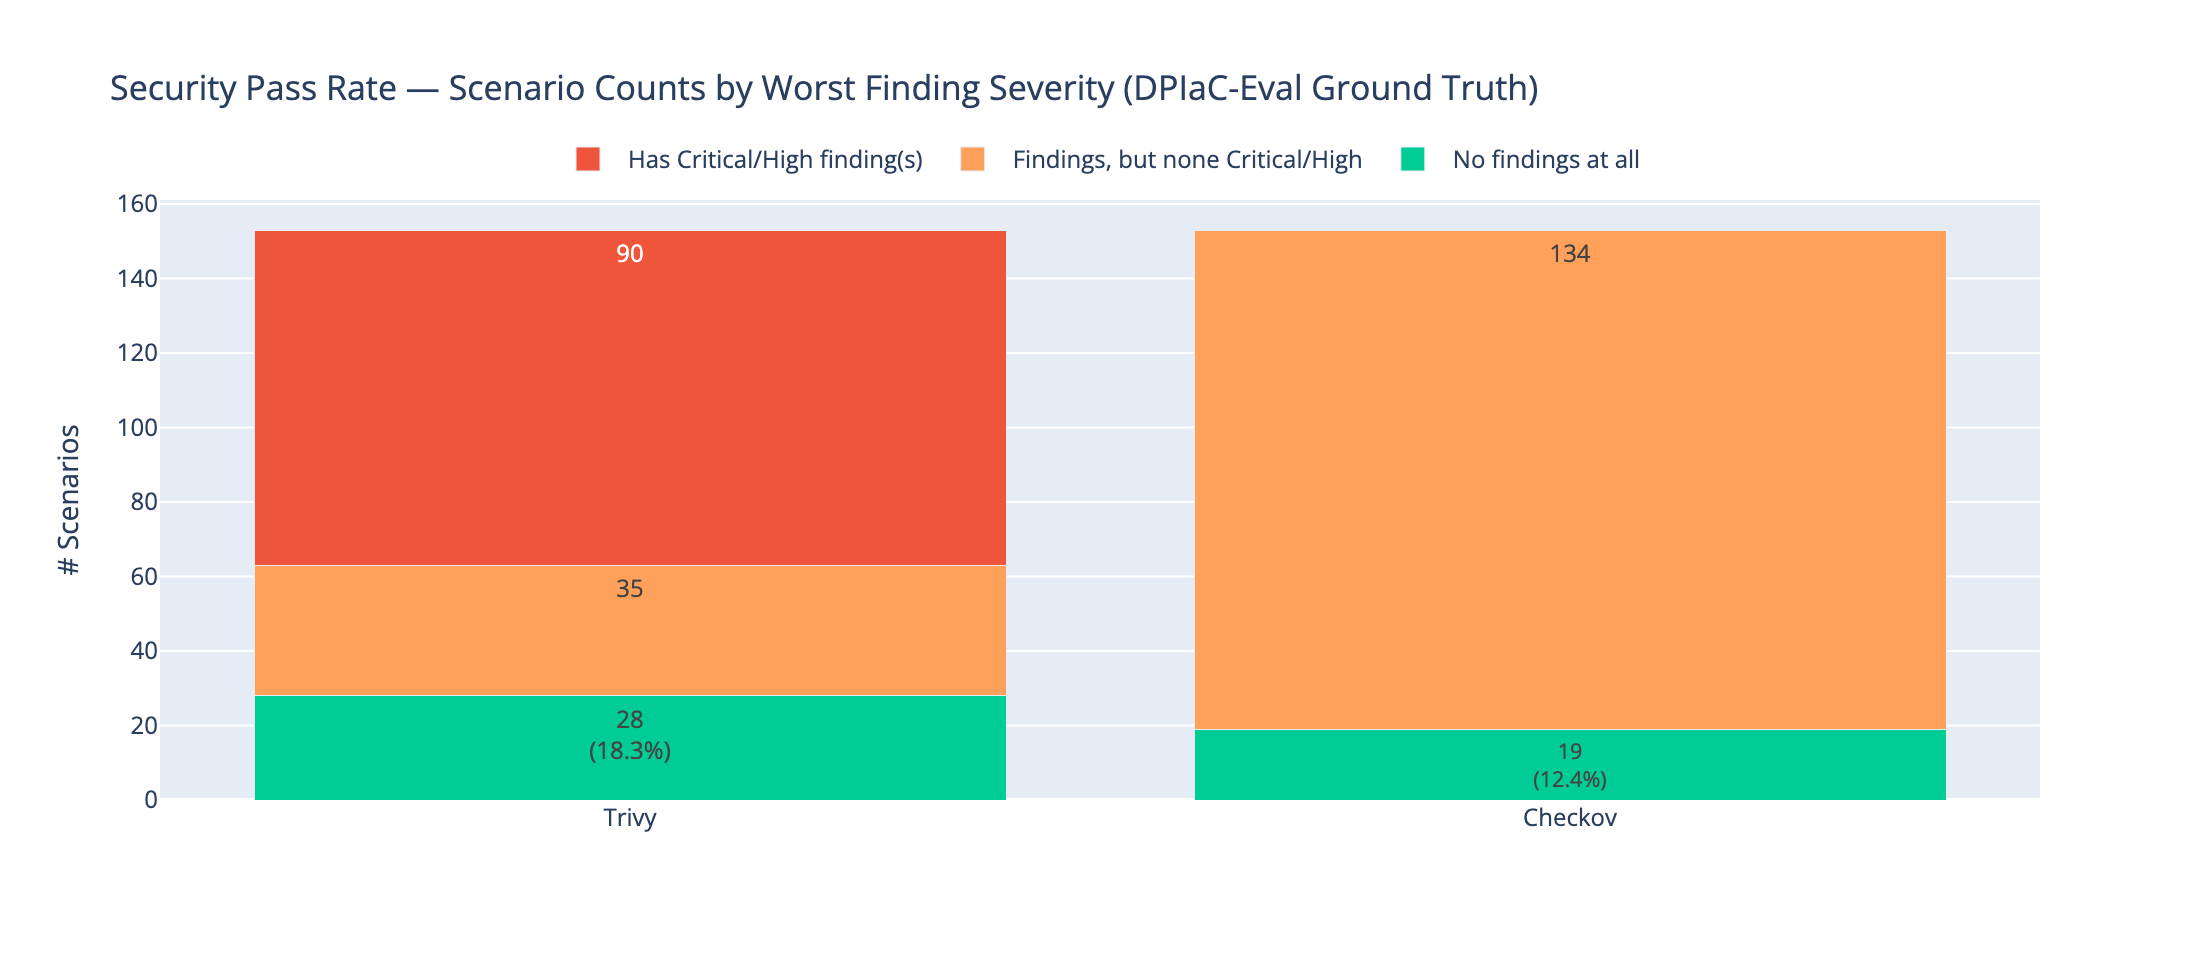

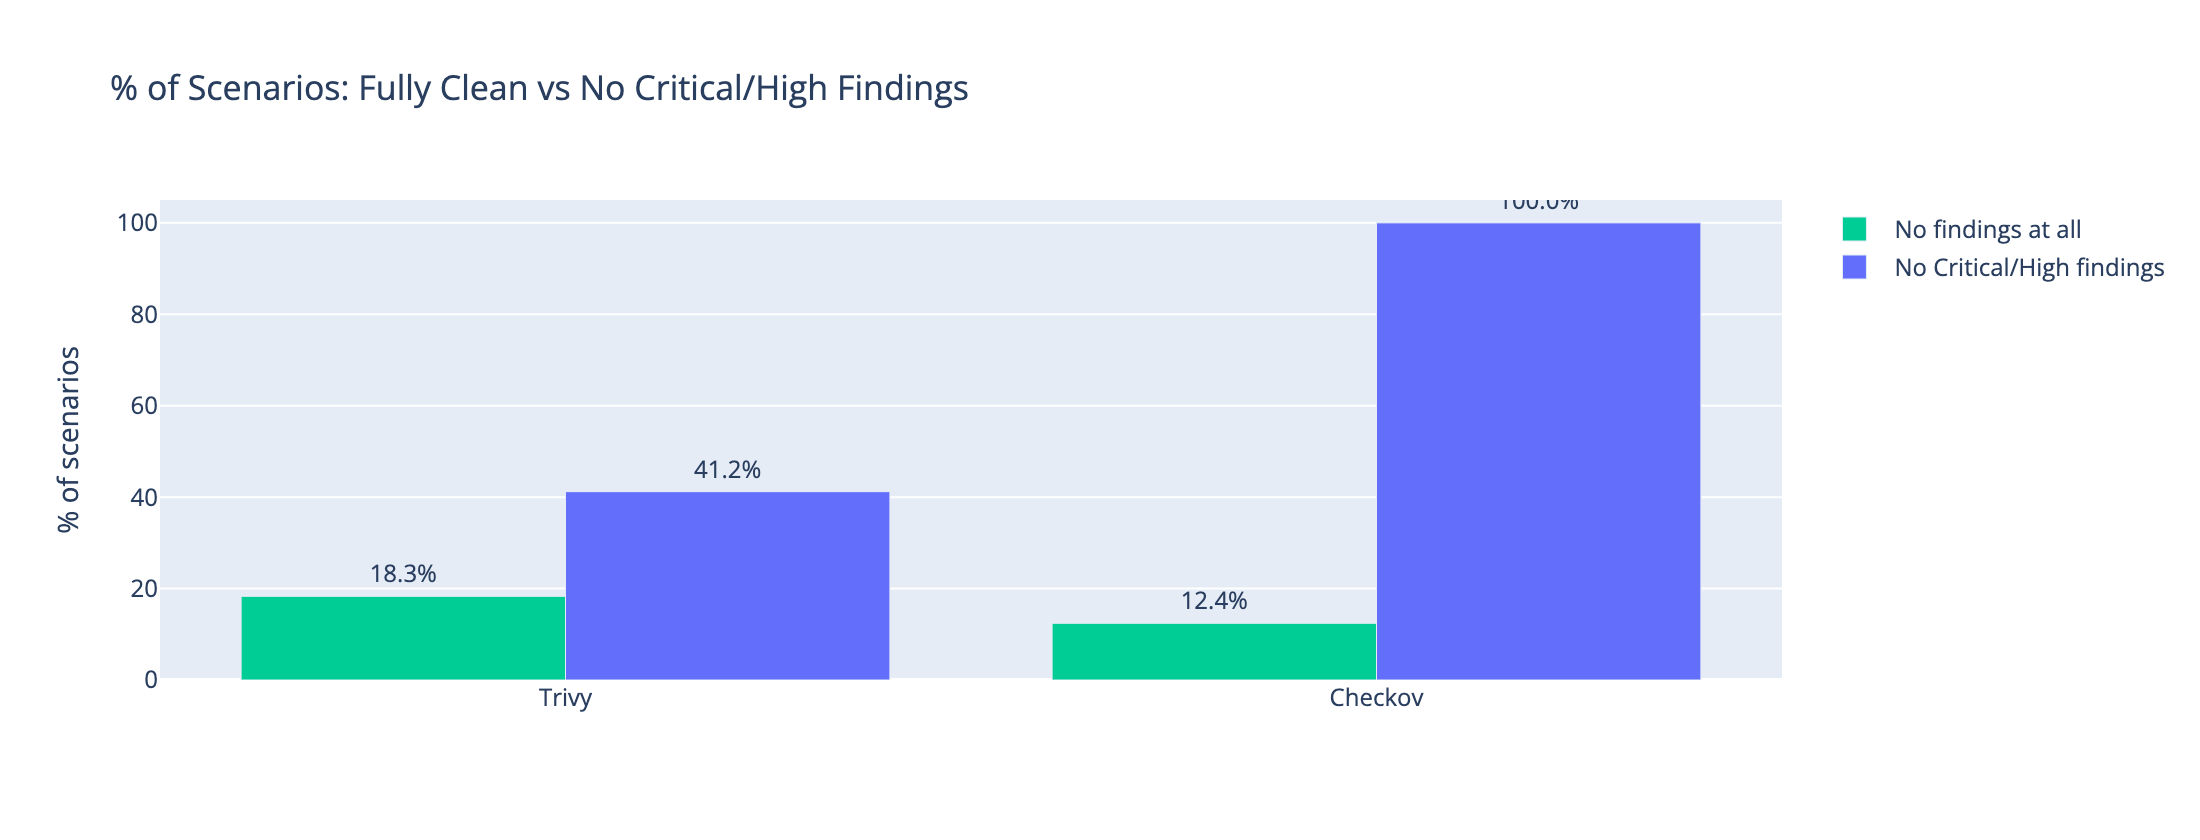


Saved -> output/dpiac_security_audit/security_passrate_summary.csv


In [27]:
def _compliance_breakdown(df_scan: pd.DataFrame, tool_name: str) -> dict:
    n = len(df_scan)
    no_findings = int(df_scan['fully_compliant'].astype(bool).sum())
    no_crit_high = int(((df_scan['severity_critical'] == 0) & (df_scan['severity_high'] == 0)).sum())
    findings_but_no_crit_high = no_crit_high - no_findings
    has_crit_high = n - no_crit_high
    return {
        'tool': tool_name, 'n_scenarios': n,
        'no_findings': no_findings,
        'findings_but_no_crit_high': findings_but_no_crit_high,
        'has_crit_high': has_crit_high,
    }

compliance_summary = pd.DataFrame([
    _compliance_breakdown(df_result, 'Trivy'),
    _compliance_breakdown(df_checkov, 'Checkov'),
])
compliance_summary['pct_no_findings'] = (
    compliance_summary['no_findings'] / compliance_summary['n_scenarios'] * 100
).round(1)
compliance_summary['pct_no_crit_high'] = (
    (compliance_summary['no_findings'] + compliance_summary['findings_but_no_crit_high'])
    / compliance_summary['n_scenarios'] * 100
).round(1)

print("=== Security pass rate — scenarios with no findings / no critical+high findings ===")
print(compliance_summary[['tool', 'n_scenarios', 'no_findings', 'pct_no_findings',
                           'findings_but_no_crit_high', 'has_crit_high', 'pct_no_crit_high']]
      .to_string(index=False))
print("\n⚠️  Checkov's severity fields are a known no-op in this environment (open-source "
      "Checkov never populates severity on failed checks -- see the note printed after the "
      "Checkov scan above). Its 'no critical/high' figure is therefore trivially 100% and "
      "should NOT be read as 'Checkov found nothing severe' -- it never tags severity at all. "
      "Trivy's severity_critical/high ARE genuinely populated and are the only trustworthy "
      "severity signal in this notebook; lean on Trivy's numbers for anything severity-weighted, "
      "and treat Checkov's 'findings vs no findings' split (fully_compliant) as its own useful "
      "signal instead.")

fig_compliance = go.Figure()
fig_compliance.add_trace(go.Bar(
    name='No findings at all', x=compliance_summary['tool'], y=compliance_summary['no_findings'],
    marker_color='#00CC96',
    text=compliance_summary.apply(lambda r: f"{r['no_findings']}<br>({r['pct_no_findings']:.1f}%)", axis=1),
    textposition='inside',
))
fig_compliance.add_trace(go.Bar(
    name='Findings, but none Critical/High', x=compliance_summary['tool'],
    y=compliance_summary['findings_but_no_crit_high'], marker_color='#FFA15A',
    text=compliance_summary['findings_but_no_crit_high'], textposition='inside',
))
fig_compliance.add_trace(go.Bar(
    name='Has Critical/High finding(s)', x=compliance_summary['tool'],
    y=compliance_summary['has_crit_high'], marker_color='#EF553B',
    text=compliance_summary['has_crit_high'], textposition='inside',
))
fig_compliance.update_layout(
    barmode='stack',
    title='Security Pass Rate — Scenario Counts by Worst Finding Severity (DPIaC-Eval Ground Truth)',
    yaxis_title='# Scenarios', height=480,
    legend=dict(orientation='h', yanchor='bottom', y=1.02, xanchor='center', x=0.5),
)
fig_compliance.show()

fig_clean_rate = go.Figure()
fig_clean_rate.add_trace(go.Bar(
    name='No findings at all', x=compliance_summary['tool'], y=compliance_summary['pct_no_findings'],
    marker_color='#00CC96', text=compliance_summary['pct_no_findings'].apply(lambda v: f'{v:.1f}%'),
    textposition='outside',
))
fig_clean_rate.add_trace(go.Bar(
    name='No Critical/High findings', x=compliance_summary['tool'], y=compliance_summary['pct_no_crit_high'],
    marker_color='#636EFA', text=compliance_summary['pct_no_crit_high'].apply(lambda v: f'{v:.1f}%'),
    textposition='outside',
))
fig_clean_rate.update_layout(
    barmode='group',
    title='% of Scenarios: Fully Clean vs No Critical/High Findings',
    yaxis_title='% of scenarios', yaxis_range=[0, 105], height=420,
)
fig_clean_rate.show()

compliance_summary.to_csv(OUTPUT_DIR / 'security_passrate_summary.csv', index=False)
print(f"\nSaved -> {OUTPUT_DIR / 'security_passrate_summary.csv'}")